# Graph metrics experimentation

This file is meant as experimentation for usage of different (heuristic) graph metrics that try to capture the hate between subreddits. The metrics are described below:

## Basic Sentiment Metrics

These metrics can be applied to both positive and negative sentiment analysis.

1. **sentiment_ratio**: Ratio of negative sentiment posts to total posts between subreddit pairs
   - Formula: $w = \frac{n_{neg}}{n_{total}}$

2. **sentiment_frequency**: Number of negative sentiment posts normalized by source subreddit activity
   - Formula: $w = \frac{n_{neg}}{n_{source\_total}}$

3. **relative_sentiment**: Sentiment posts relative to the subreddit's average sentiment activity
   - Formula: $w = \frac{n_{neg}/n_{total}}{n_{source\_neg}/n_{source\_total}}$

4. **sentiment_intensity**: Combination of sentiment ratio and absolute count
   - Formula: $w = \frac{n_{neg}}{n_{total}} \cdot \log(1 + n_{neg})$

5. **sentiment_count**: Raw negative sentiment post count
   - Formula: $w = n_{neg}$

6. **source_total_sentiment**: Total negative sentiment posts from source subreddit (to all targets)
   - Formula: $w = n_{source\_neg}$

7. **source_activity_weighted**: Weighted by source subreddit activity
   - Formula: $w = n_{neg} \cdot \log(1 + n_{source\_total})$

8. **target_activity_weighted**: Weighted by target subreddit activity
   - Formula: $w = n_{neg} \cdot \log(1 + n_{target\_total})$

9. **combined_activity**: Combined activity (source × target)
   - Formula: $w = n_{neg} \cdot \log(1 + n_{source\_total}) \cdot \log(1 + n_{target\_total})$

10. **subreddit_size_ratio**: Ratio of source subreddit activity to target subreddit activity
    - Formula: $w = n_{neg} \cdot \frac{n_{source\_total}}{n_{target\_total}}$

## Hate-Focused Metrics

These metrics analyze negative sentiment using linguistic features from LIWC and VADER analysis.

1. **direct_hate_score**: Emotional hate indicators
   - Formula: $w = \text{mean}\left(\frac{\text{LIWC\_negemo} + \text{LIWC\_anger} + \text{LIWC\_swear} + \text{LIWC\_negate}}{4}\right)$

2. **aggressive_communication**: Aggressive language patterns
   - Formula: $w = \text{mean}\left(\frac{\text{uppercase} + \text{special\_chars} + \text{LIWC\_certain} + \text{vader\_negative}}{4}\right)$

3. **emotional_toxicity**: Negative emotional intensity
   - Formula: $w = \text{mean}\left(\frac{\text{vader\_negative} + \text{LIWC\_negemo} + \text{LIWC\_anger} + \text{LIWC\_anxiety} + \text{LIWC\_sad} + \text{LIWC\_swear}}{6}\right)$

4. **social_conflict**: Social conflict indicators
   - Formula: $w = \text{mean}\left(\frac{\text{LIWC\_you} + \text{LIWC\_they} + \text{LIWC\_excl} + \min(\frac{\text{LIWC\_we}}{\text{LIWC\_they}}, 2)}{4}\right)$
   

5. **comprehensive_hate**: Multi-dimensional hate score combining all hate indicators
   - Formula: $w = \text{mean}\left(0.4 \cdot \text{emotional\_hate} + 0.25 \cdot \text{communication\_aggression} + 0.2 \cdot \text{social\_conflict} + 0.1 \cdot \min(\frac{\text{LIWC\_we}}{\text{LIWC\_they}}, 2) + 0.05 \cdot \max(-\text{vader\_compound}, 0)\right)$

6. **hate_intensity_weighted**: Comprehensive hate score weighted by post length
   - Formula: $w = \text{mean}\left(\text{comprehensive\_hate} \cdot \log(1 + \text{char\_count}) \cdot \log(1 + \text{word\_count})\right)$

## Positive-Focused Metrics

These metrics analyze positive sentiment using linguistic features from LIWC and VADER analysis.

1. **positive_emotion**: Positive emotional indicators
   - Formula: $w = \text{mean}\left(\frac{\text{LIWC\_posemo} + \text{vader\_positive} + \max(\text{vader\_compound}, 0)}{3}\right)$

2. **social_connection**: Social connection indicators
   - Formula: $w = \text{mean}\left(\frac{\text{LIWC\_social} + \text{LIWC\_family} + \text{LIWC\_friends} + \text{LIWC\_humans}}{4}\right)$

3. **positive_activity**: Positive activity indicators
   - Formula: $w = \text{mean}\left(\frac{\text{LIWC\_achiev} + \text{LIWC\_leisure} + \text{LIWC\_assent}}{3}\right)$

4. **inclusive_language**: Inclusive language indicators
   - Formula: $w = \text{mean}\left(\frac{\text{LIWC\_we} + \text{LIWC\_incl}}{2}\right)$

5. **comprehensive_positive**: Multi-dimensional positive score combining all positive indicators
   - Formula: $w = \text{mean}\left(0.4 \cdot \text{positive\_emotion} + 0.25 \cdot \text{social\_connection} + 0.2 \cdot \text{positive\_activity} + 0.15 \cdot \text{inclusive\_language}\right)$

Note: The $\min(\frac{\text{LIWC\_we}}{\text{LIWC\_they}}, 2)$ this ratio captures in-group ("we") vs out-group ("they") language patterns

In [1]:
import sys
import os

project_root = os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..'))
sys.path.insert(0, project_root)

In [2]:
from src.utils.data_utils import load_reddit_graph
import random
import numpy as np

G = load_reddit_graph()
random.seed(42)
np.random.seed(42)

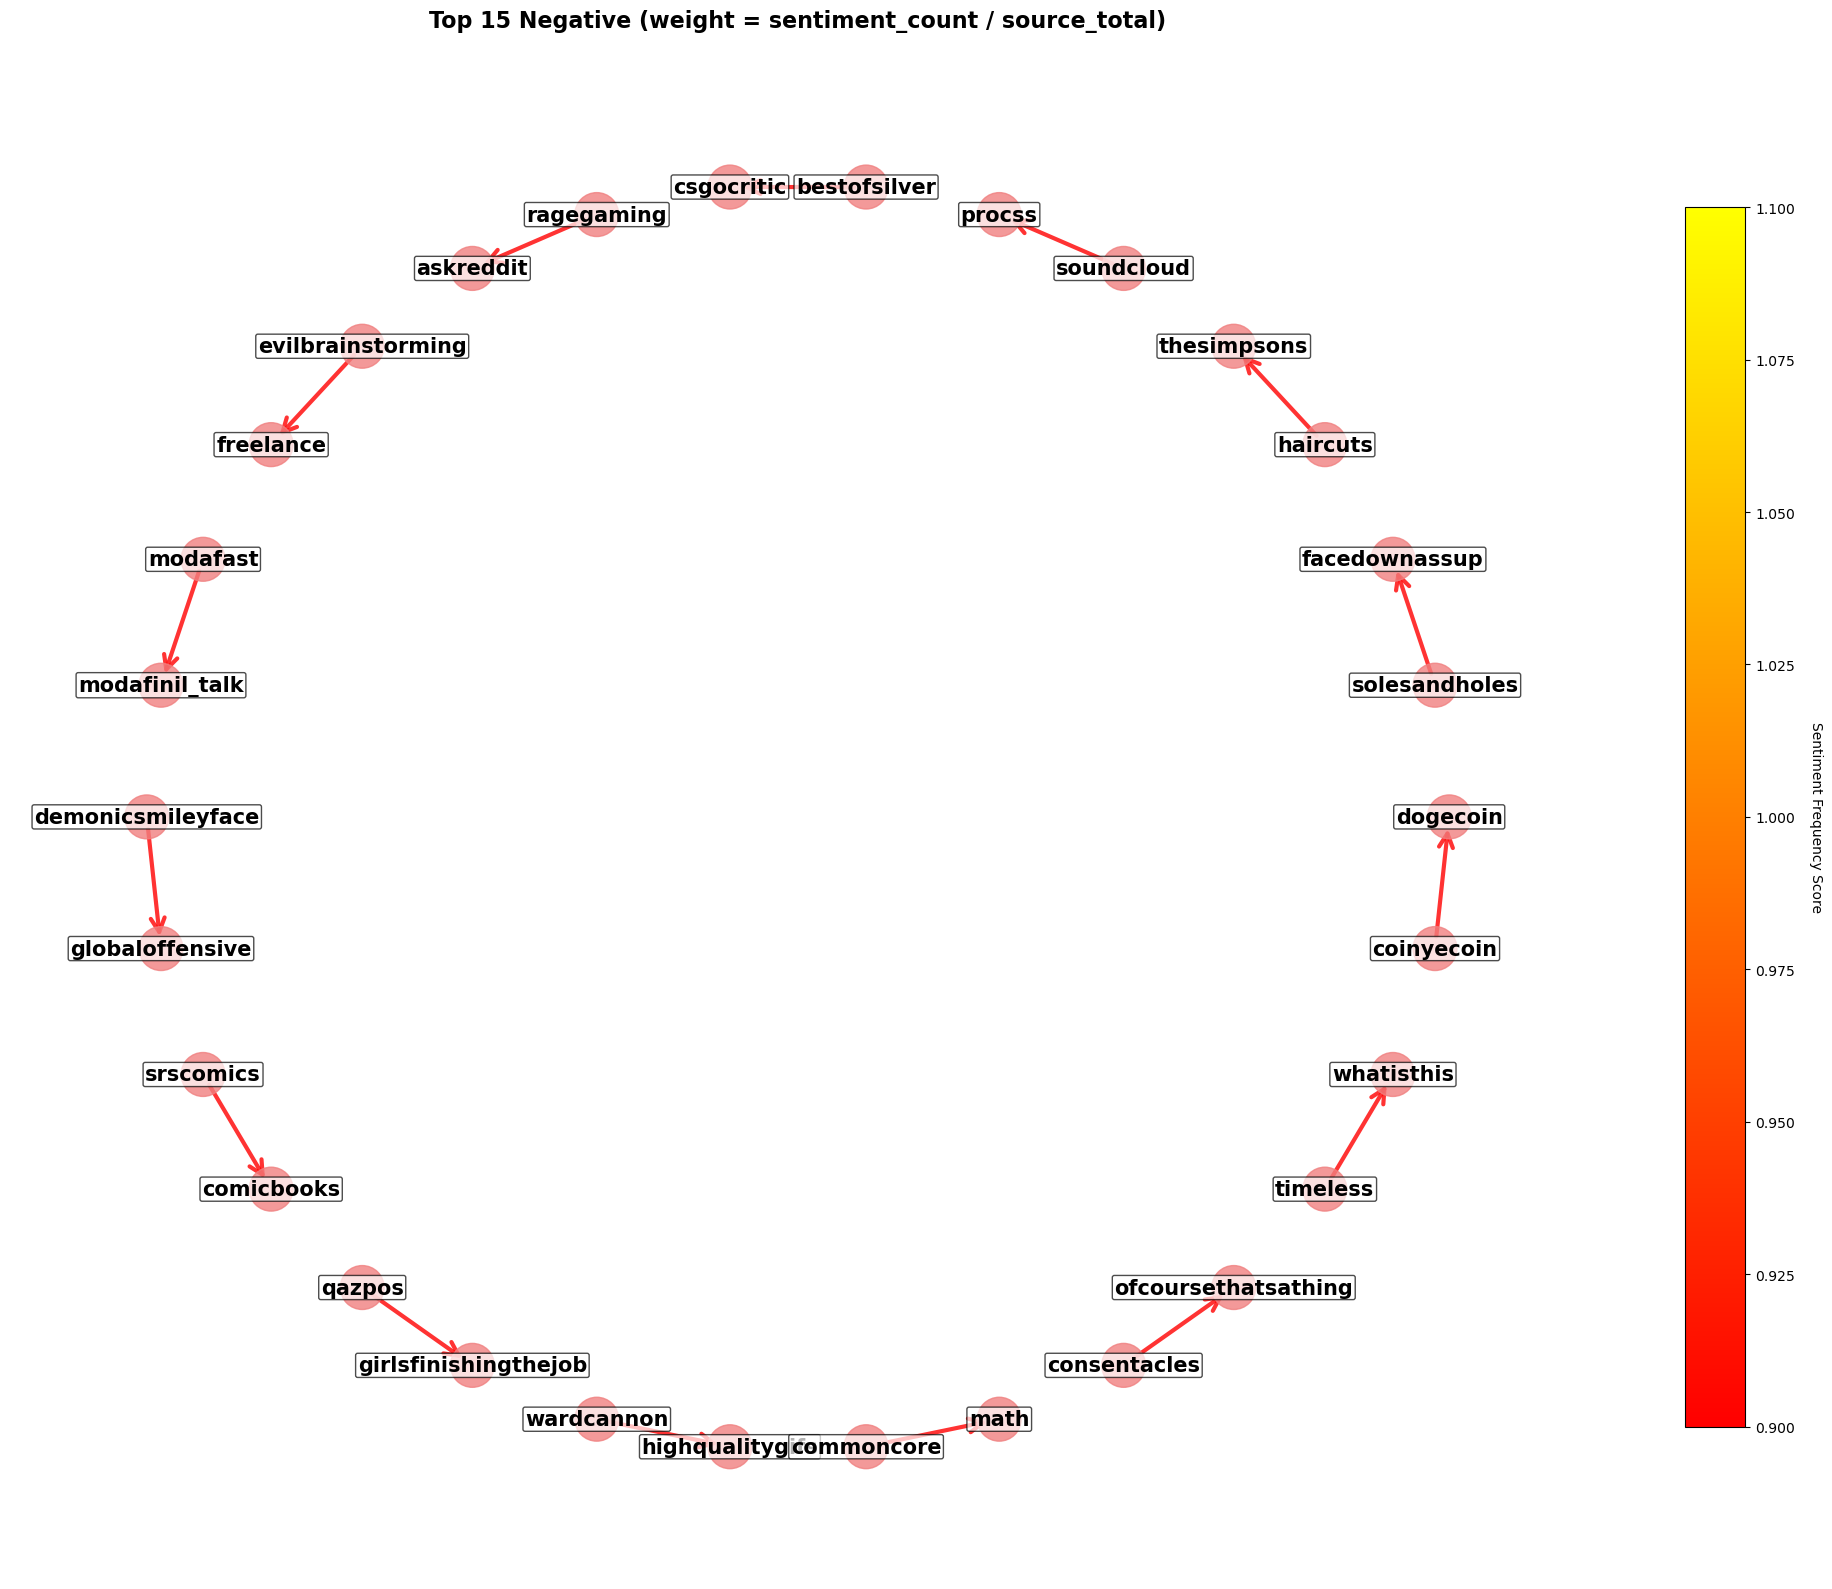

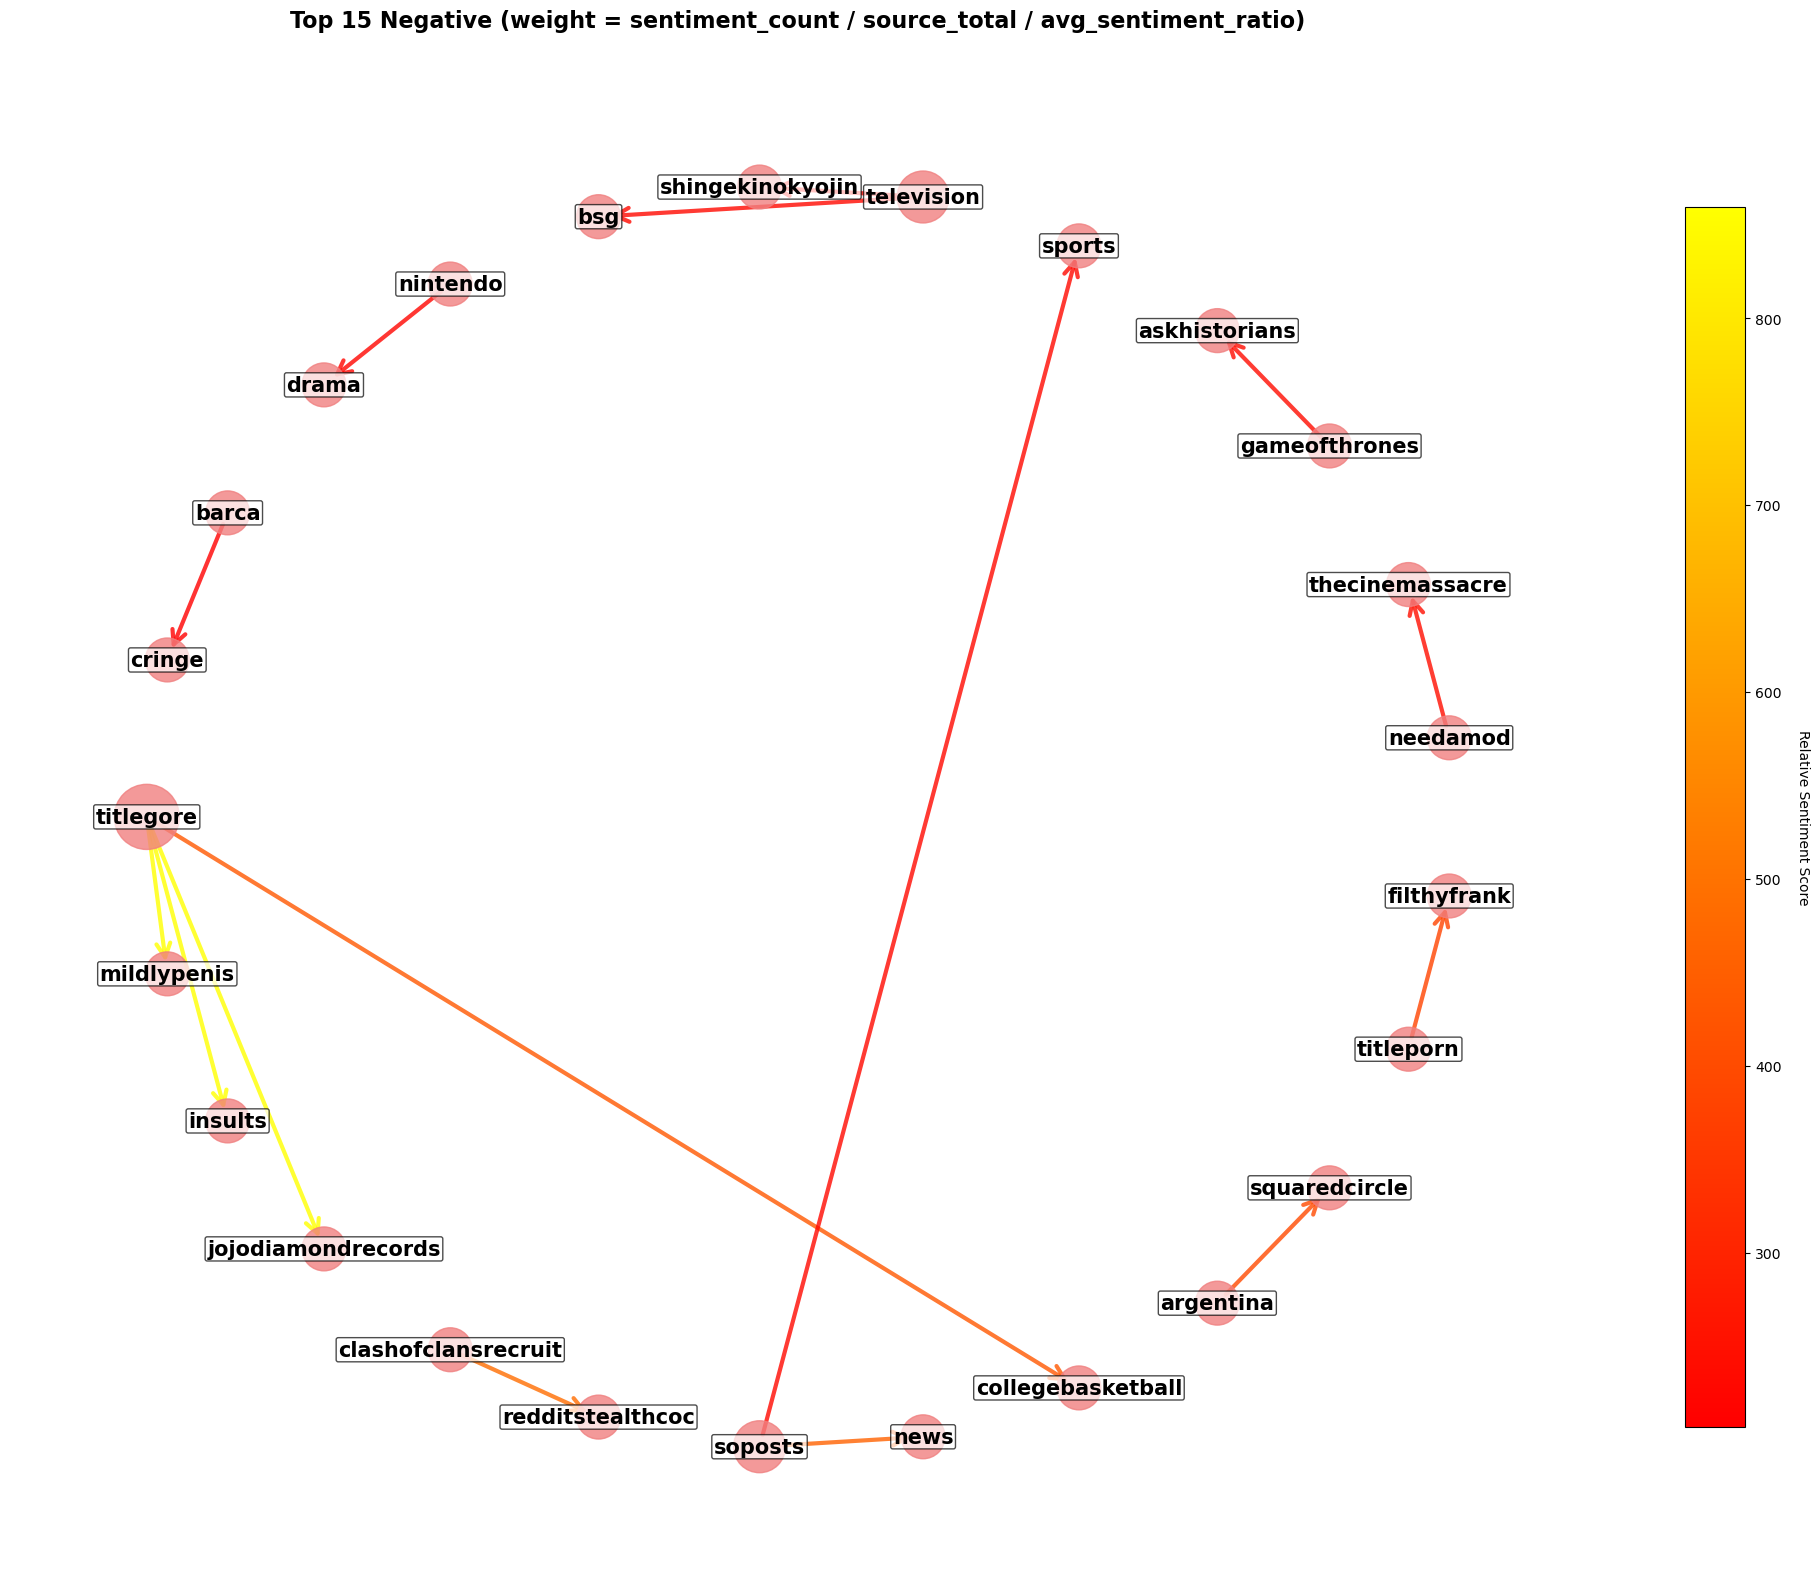

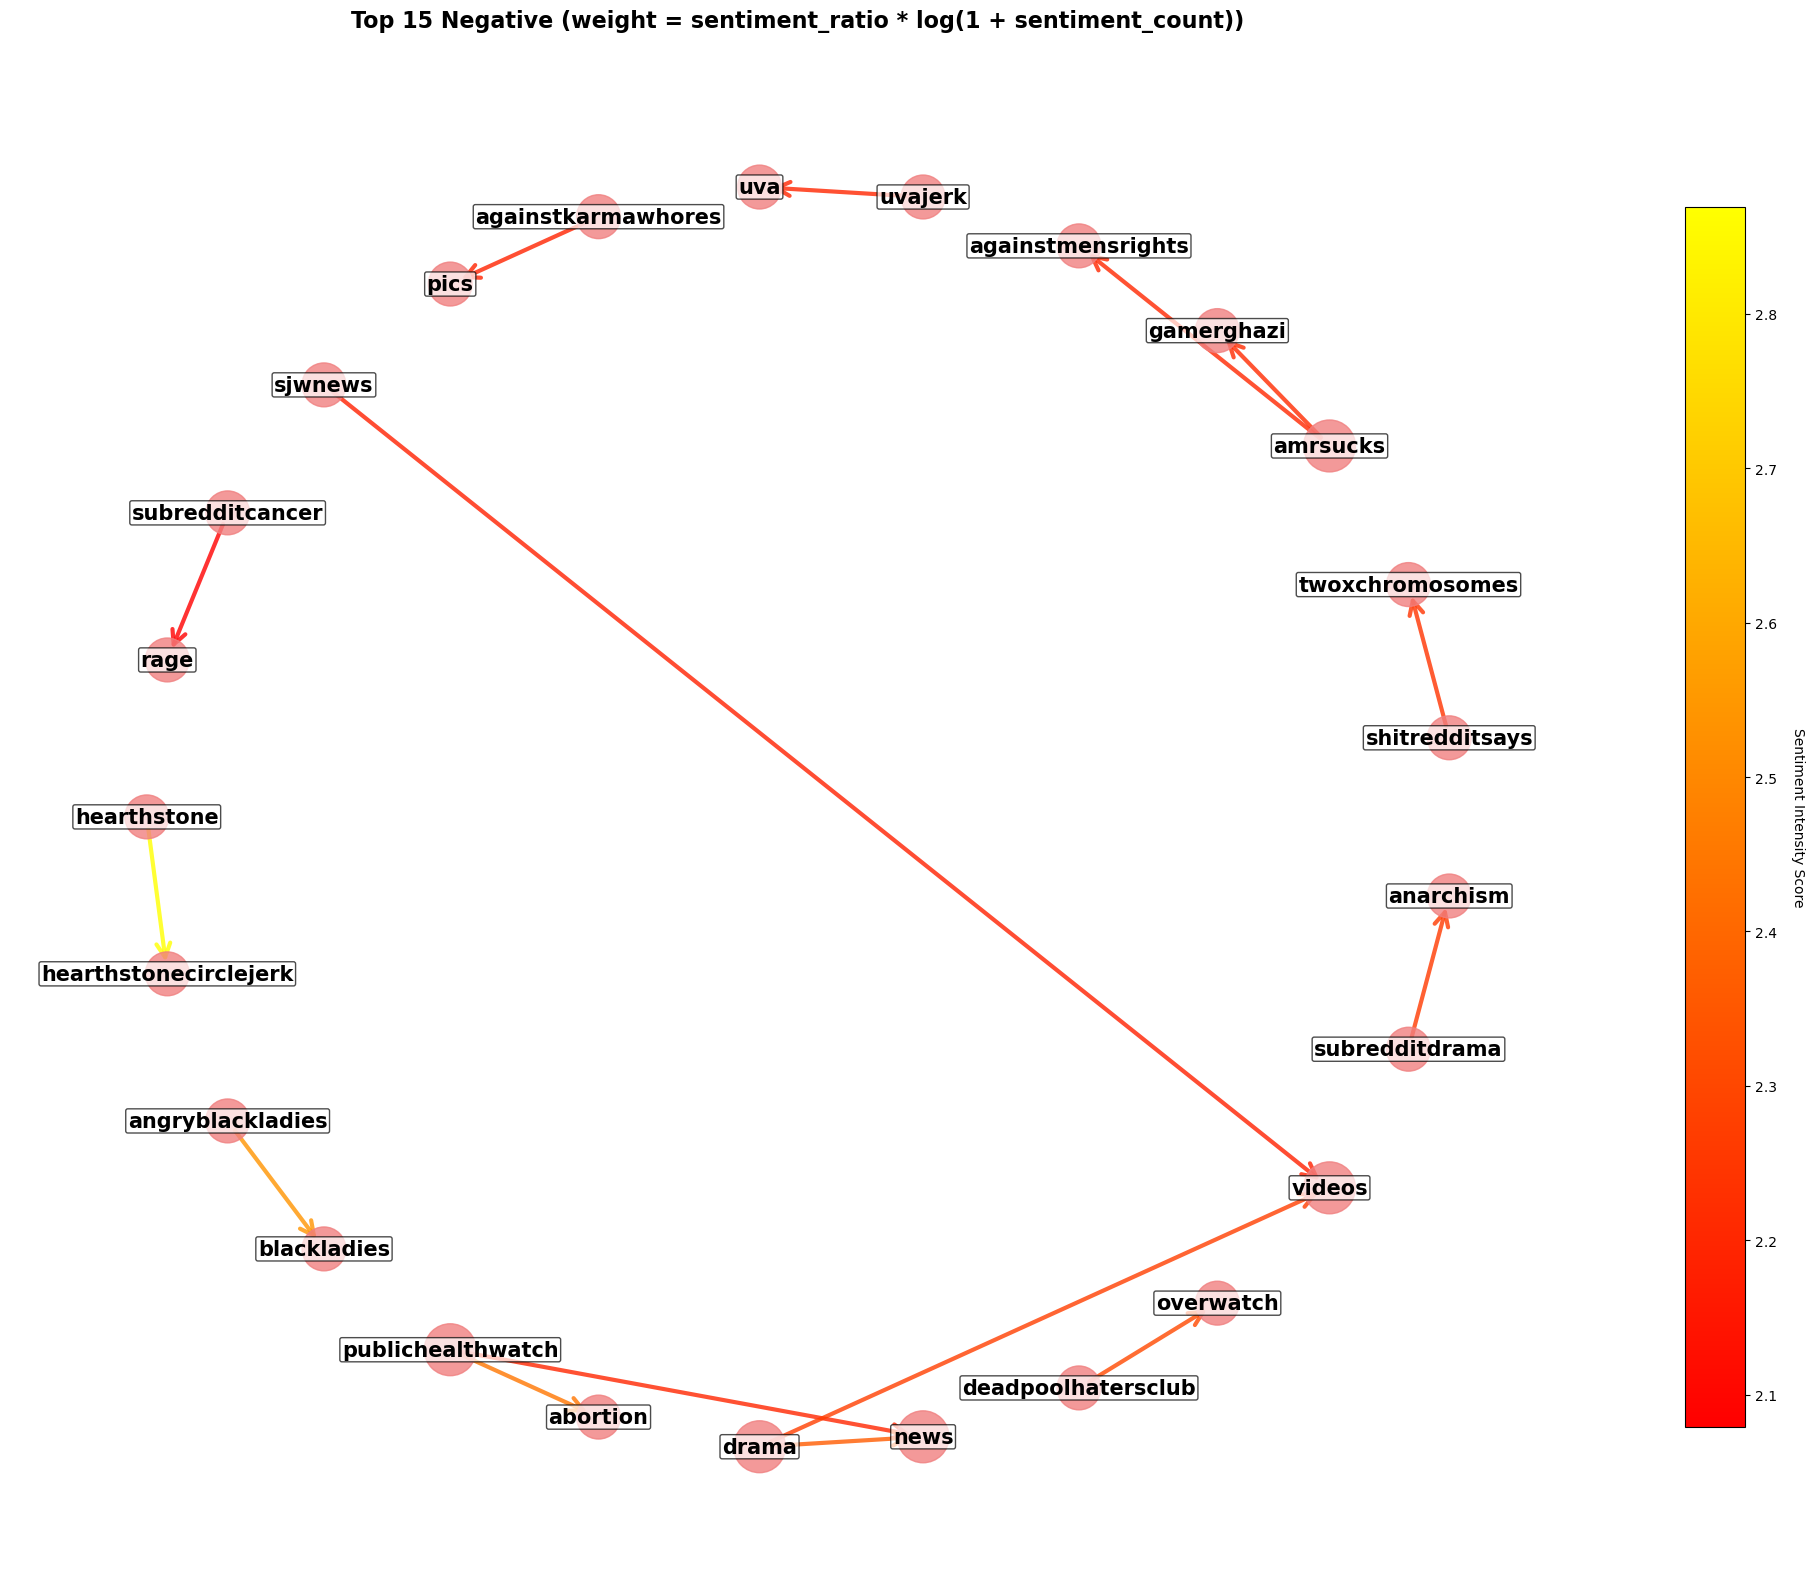

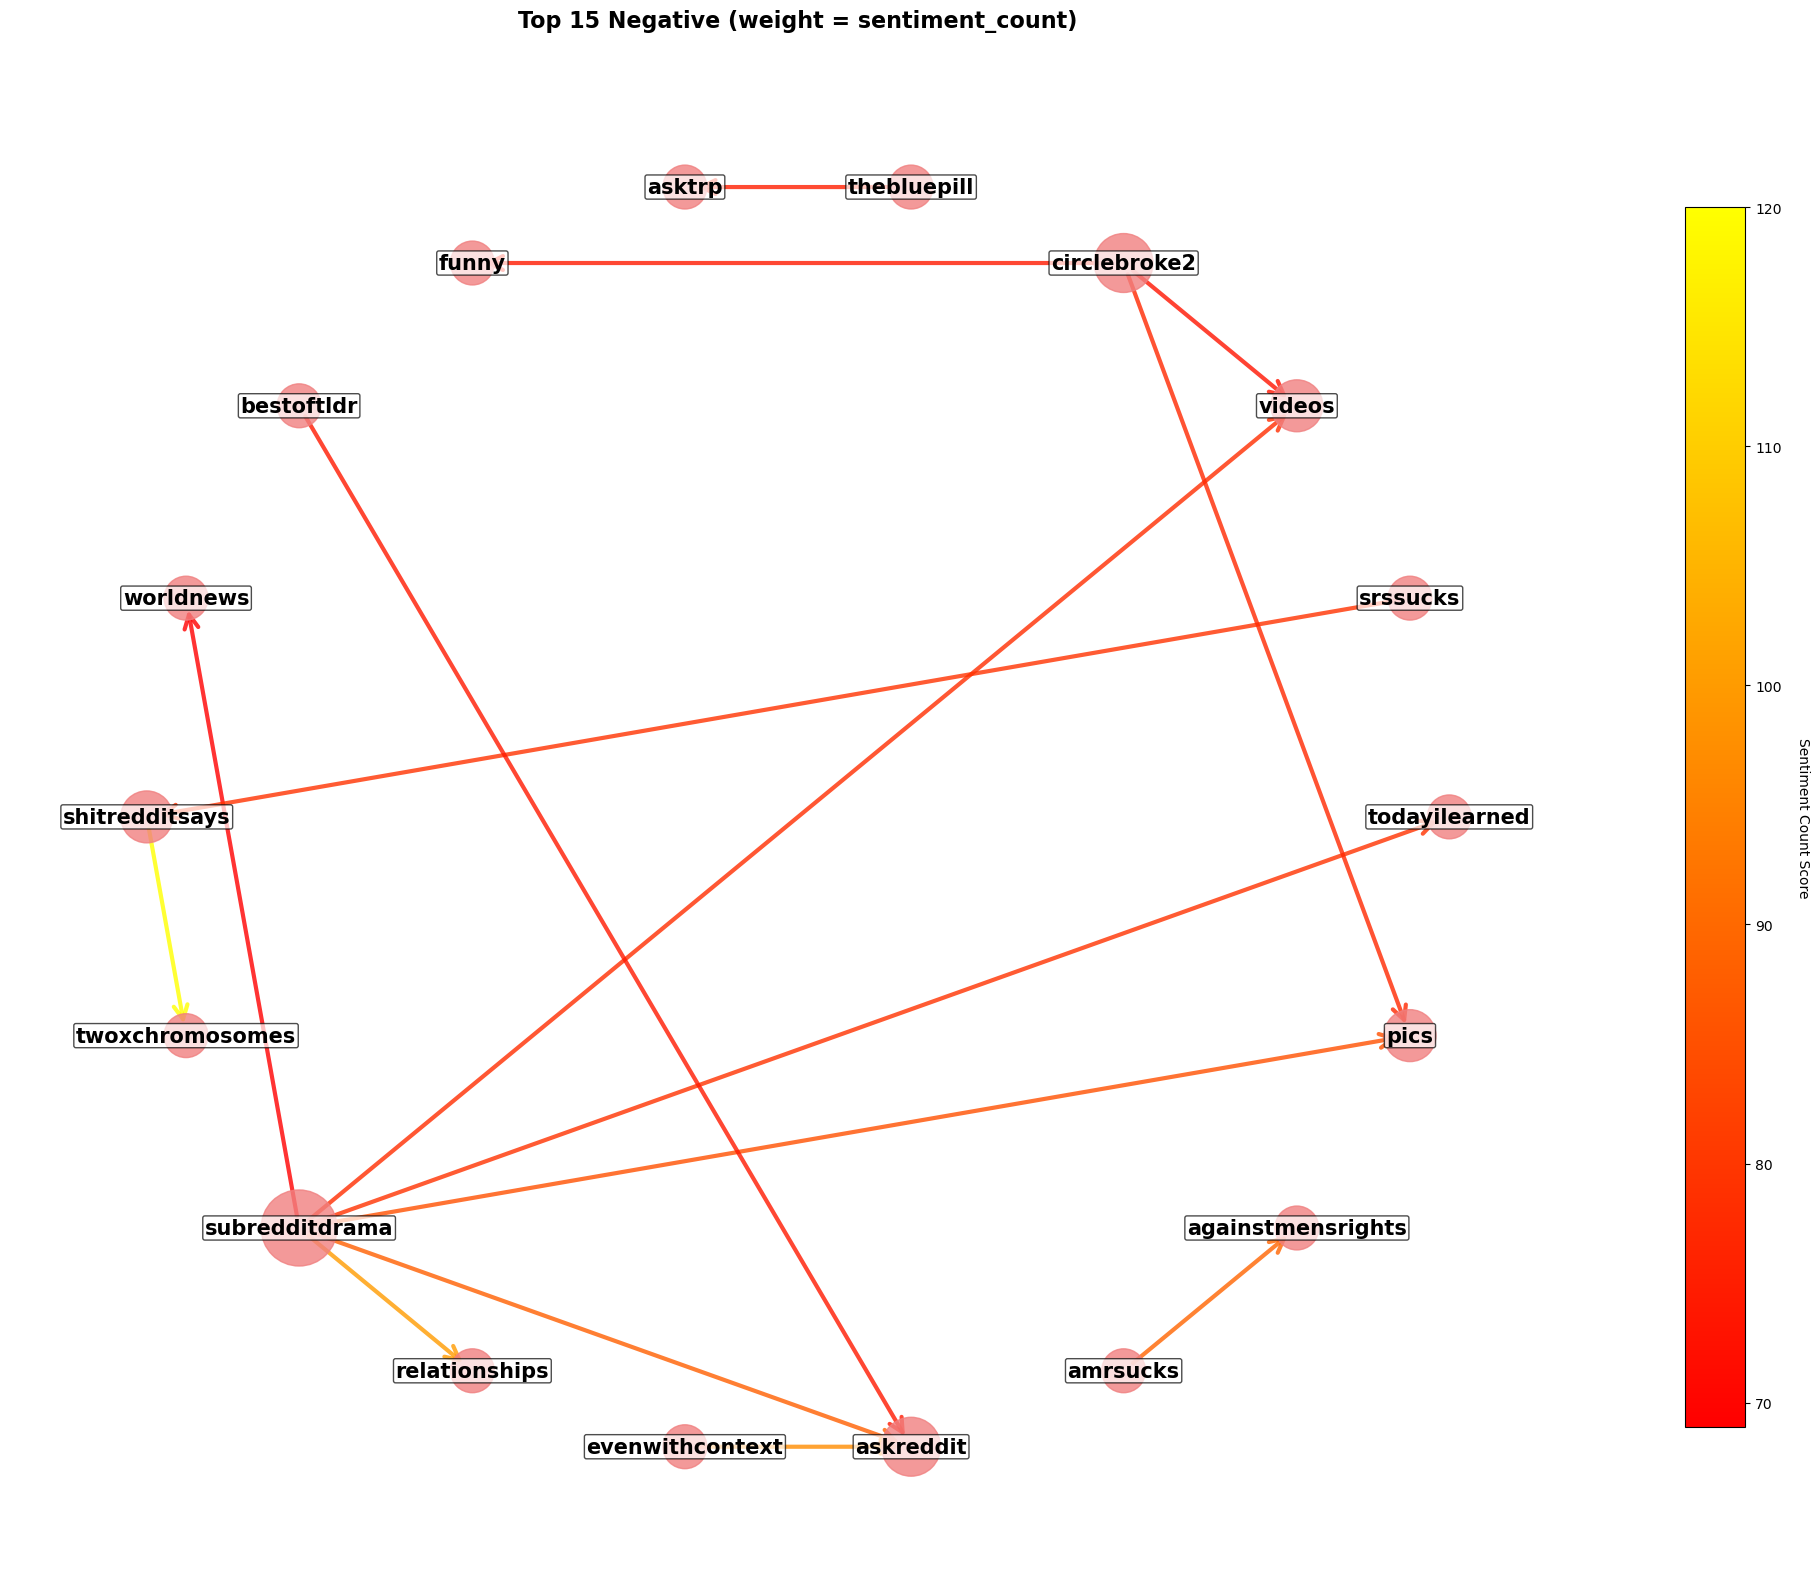

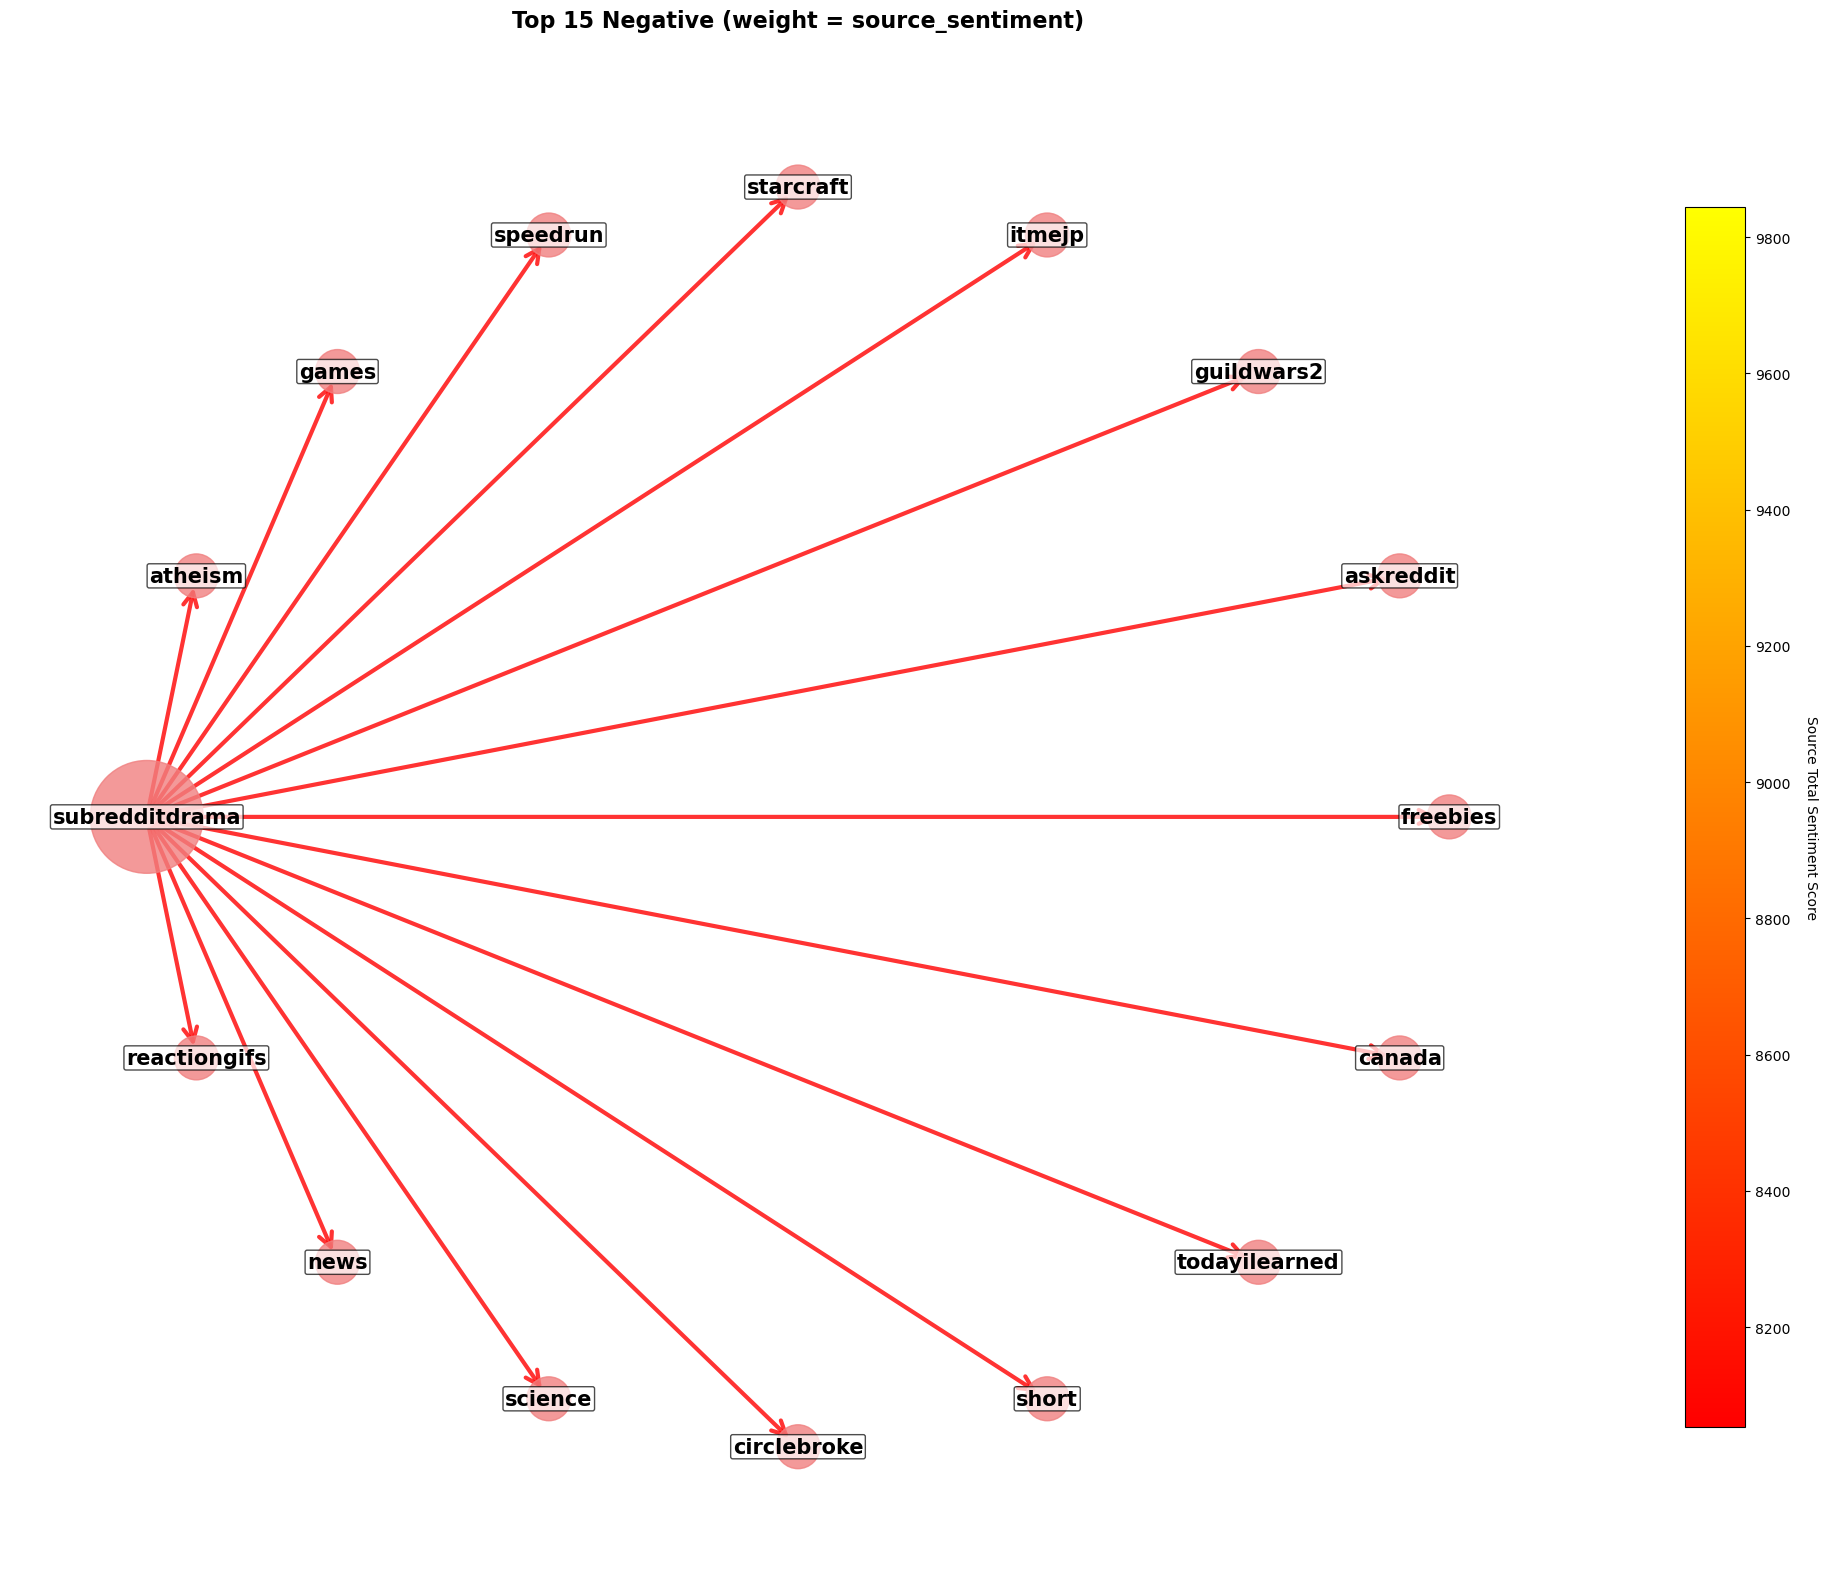

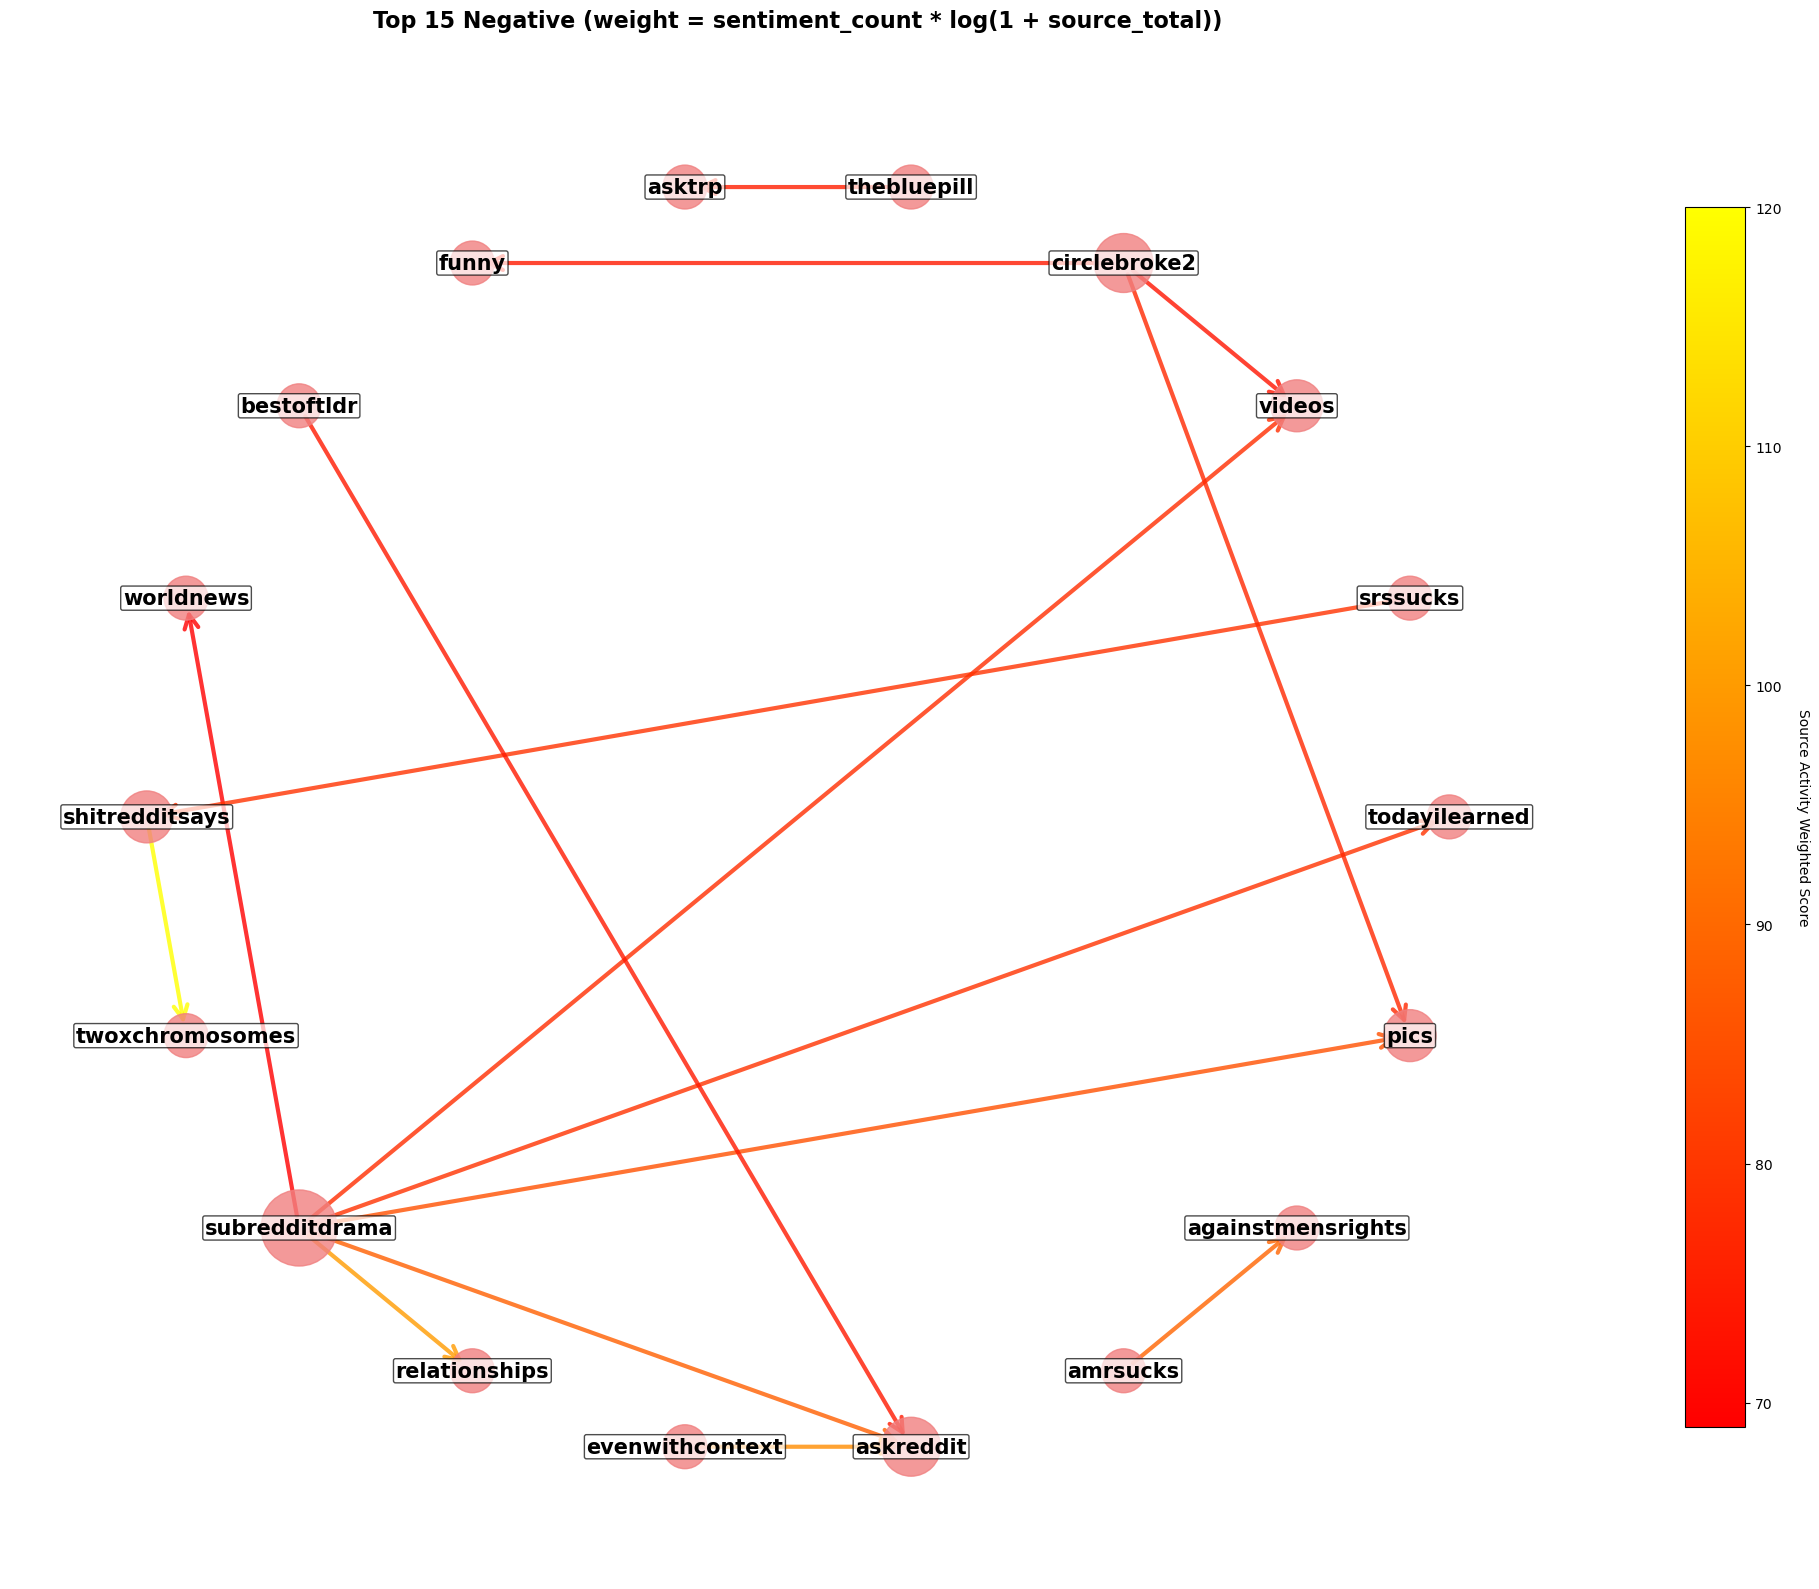

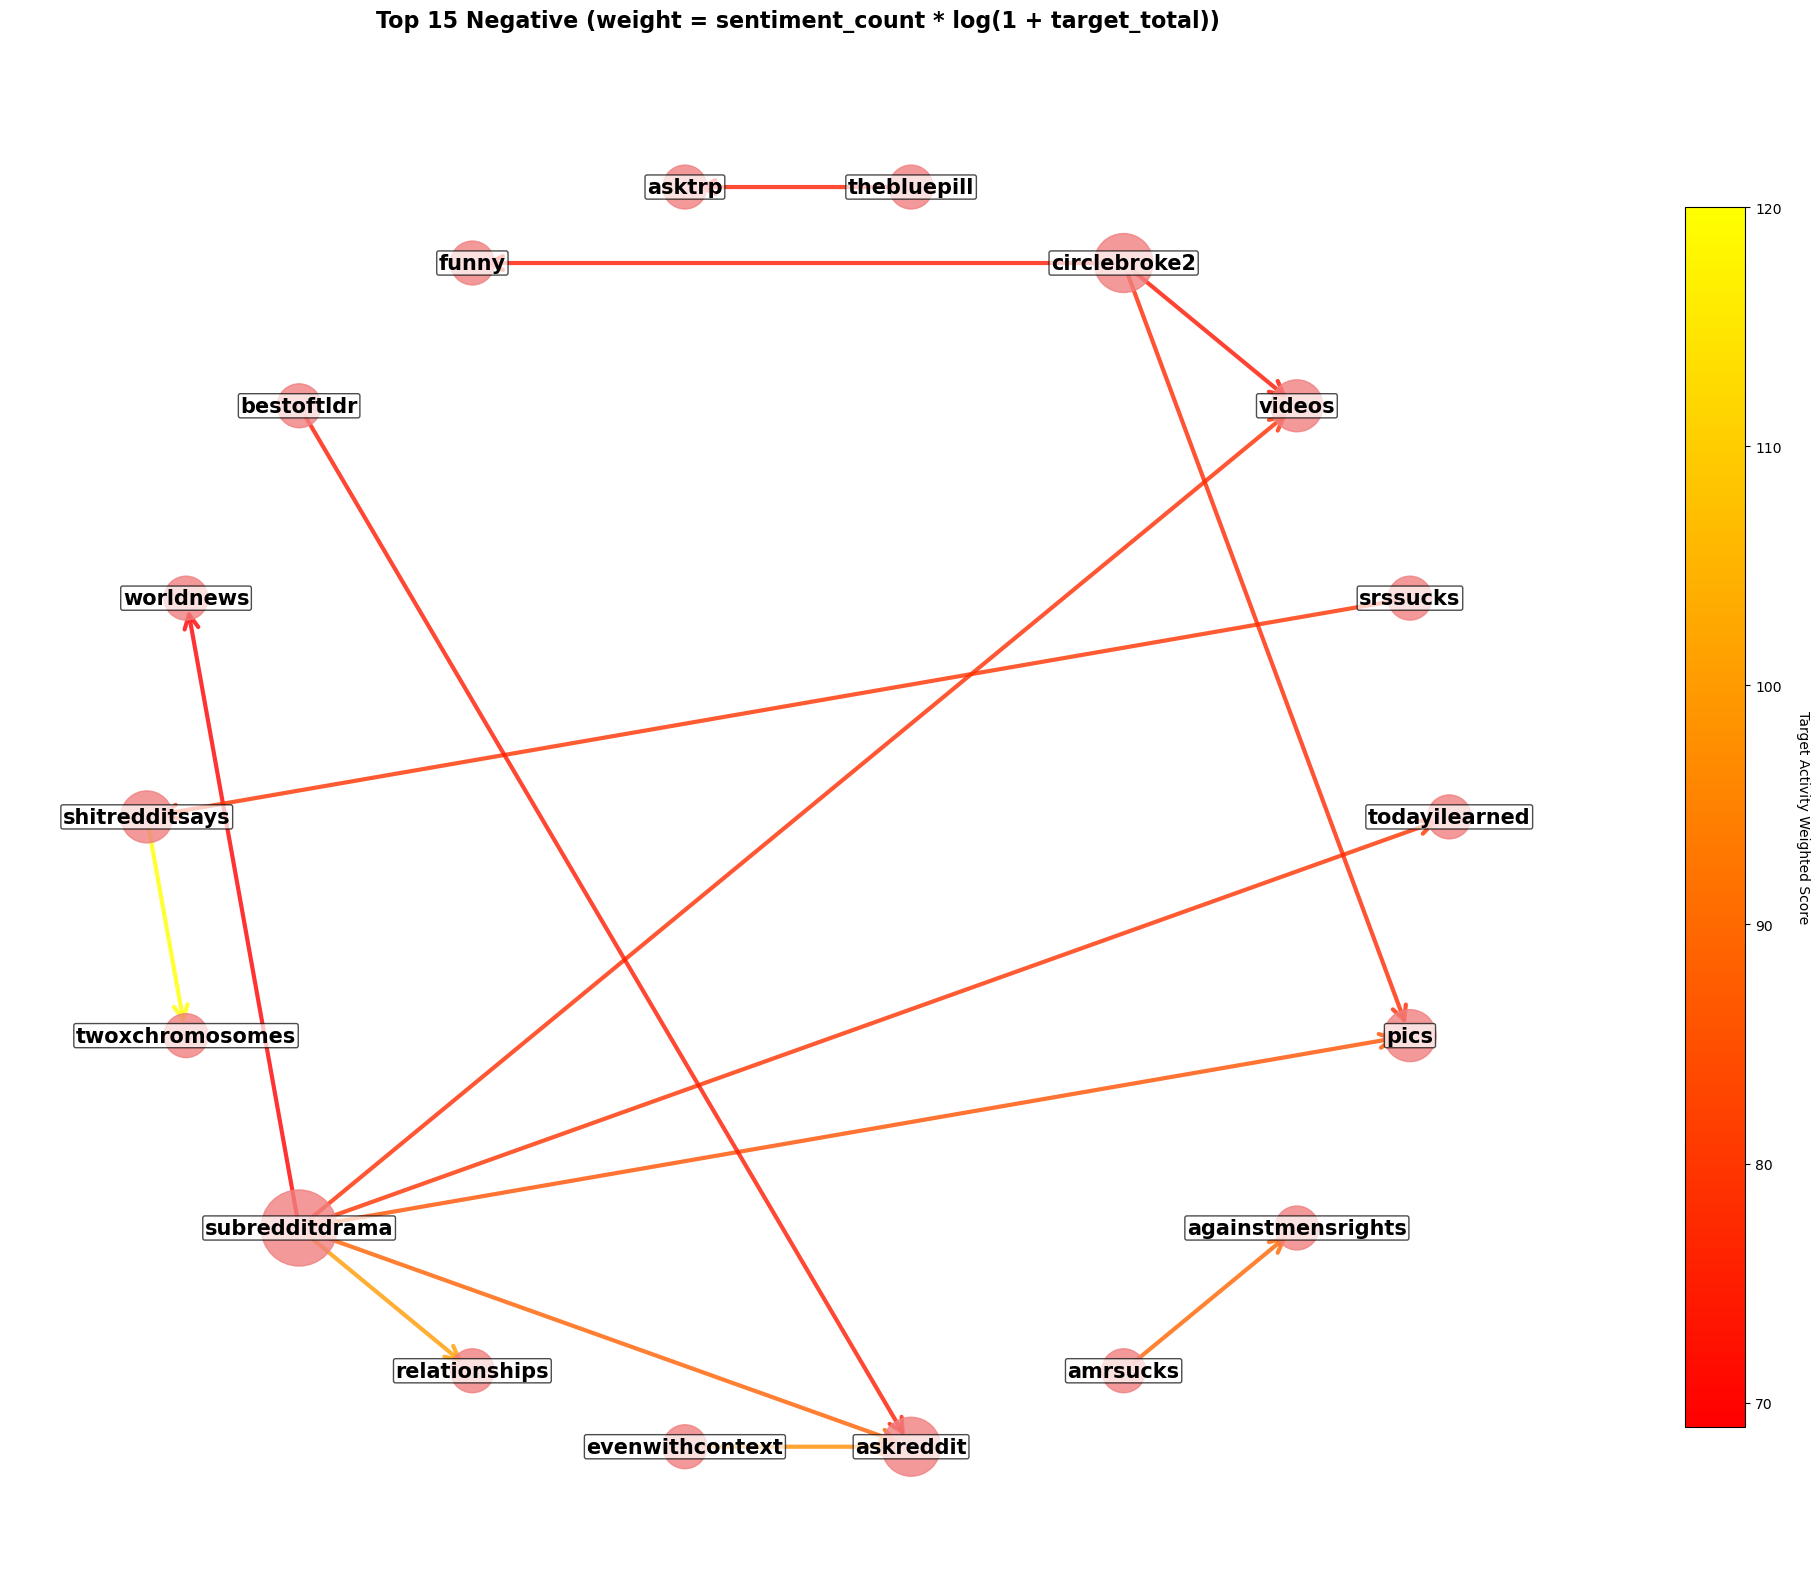

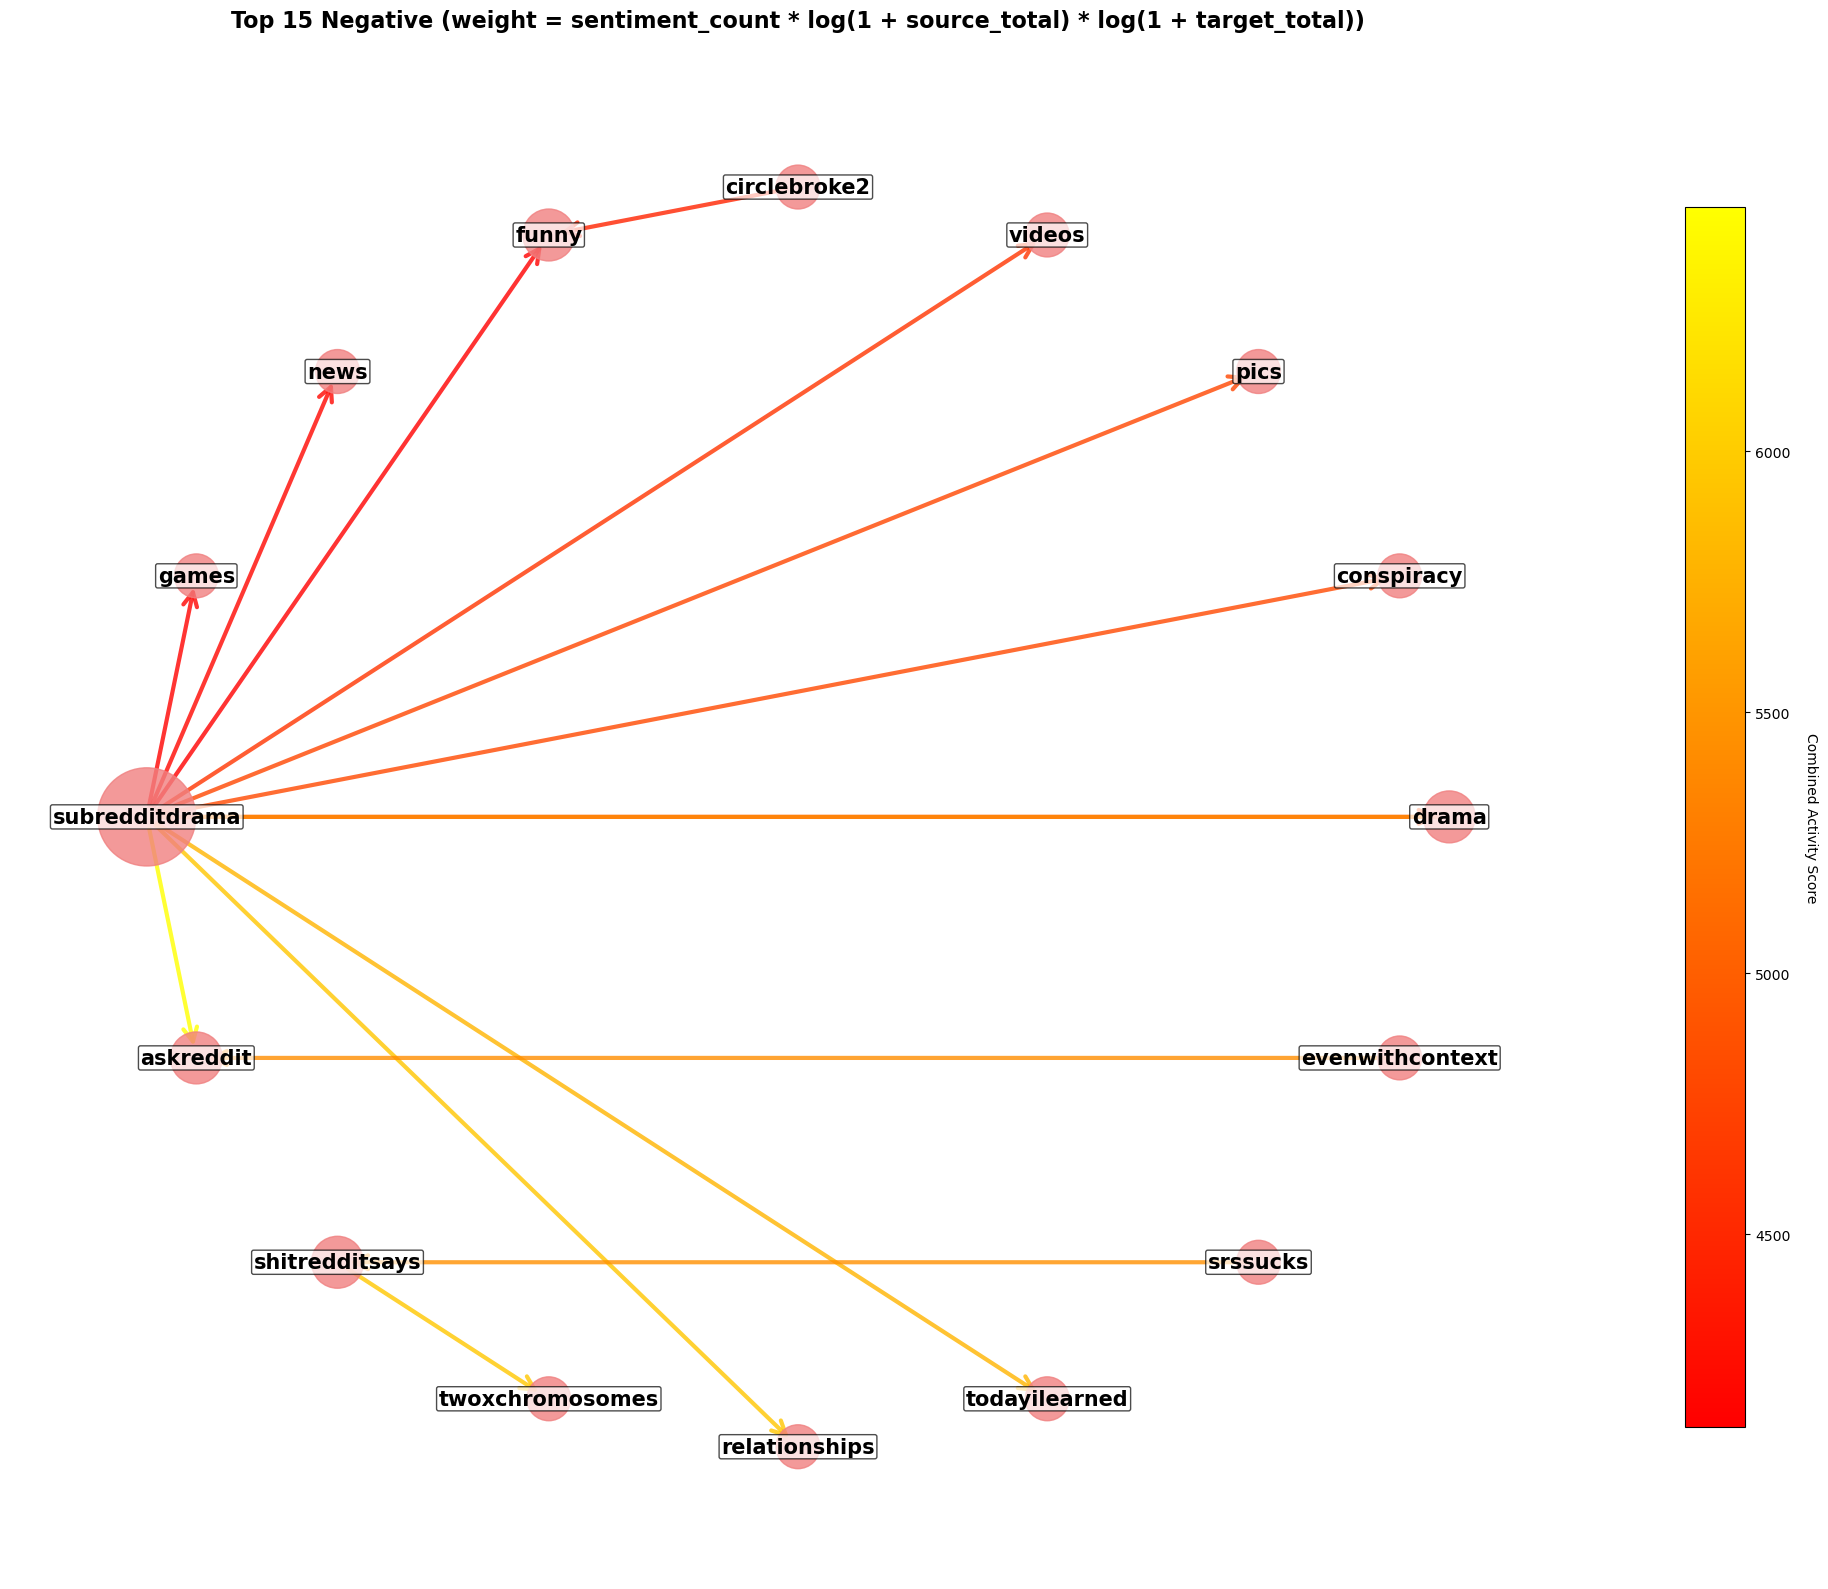

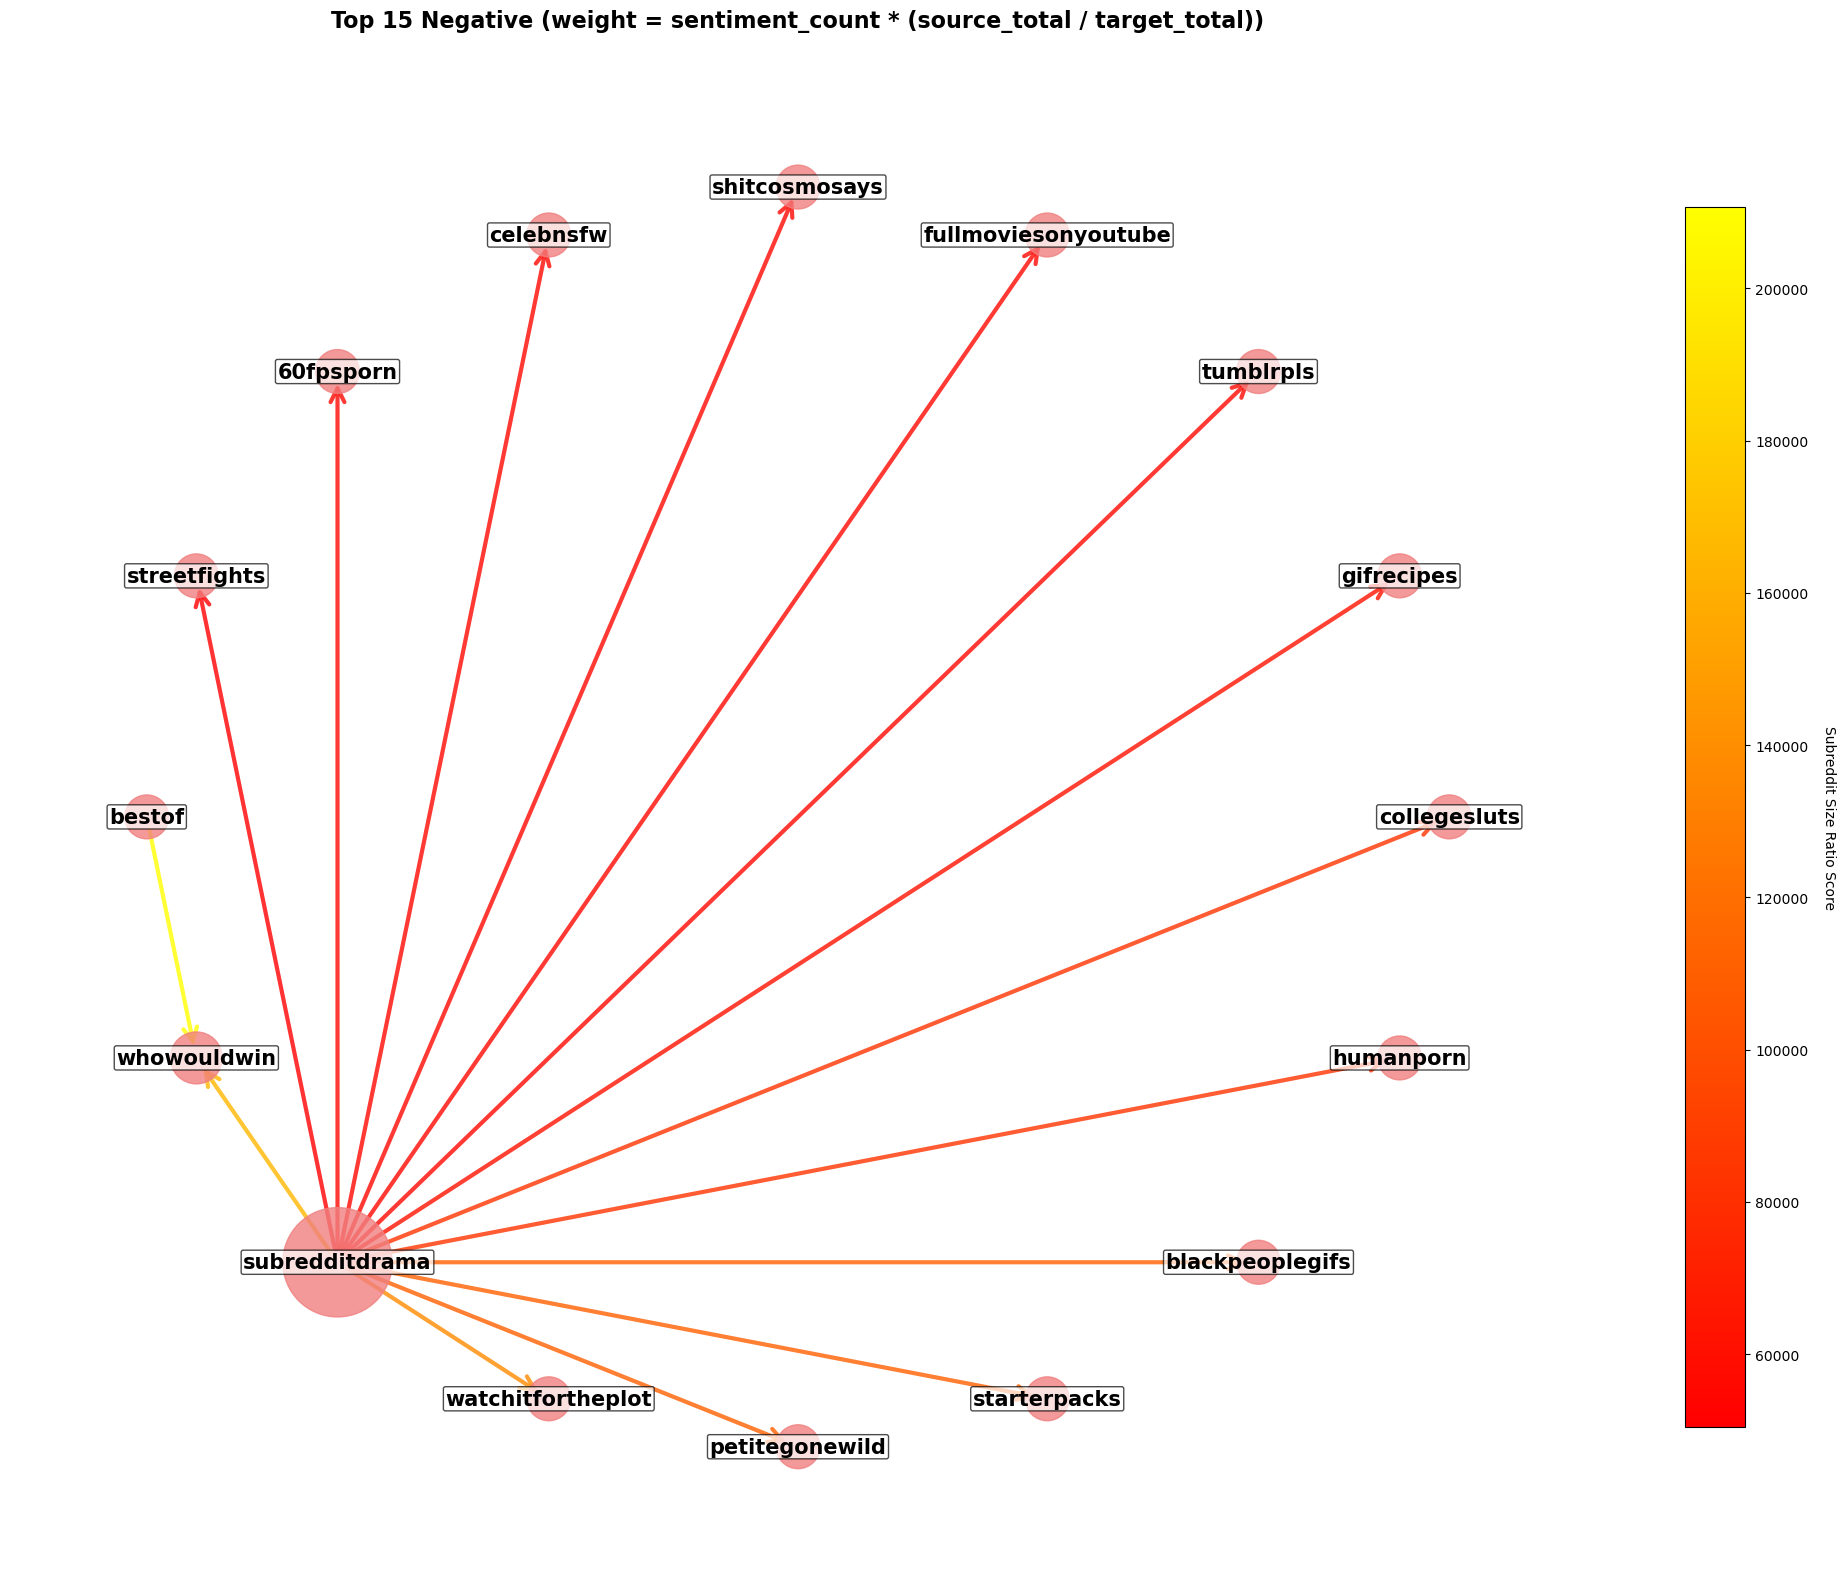

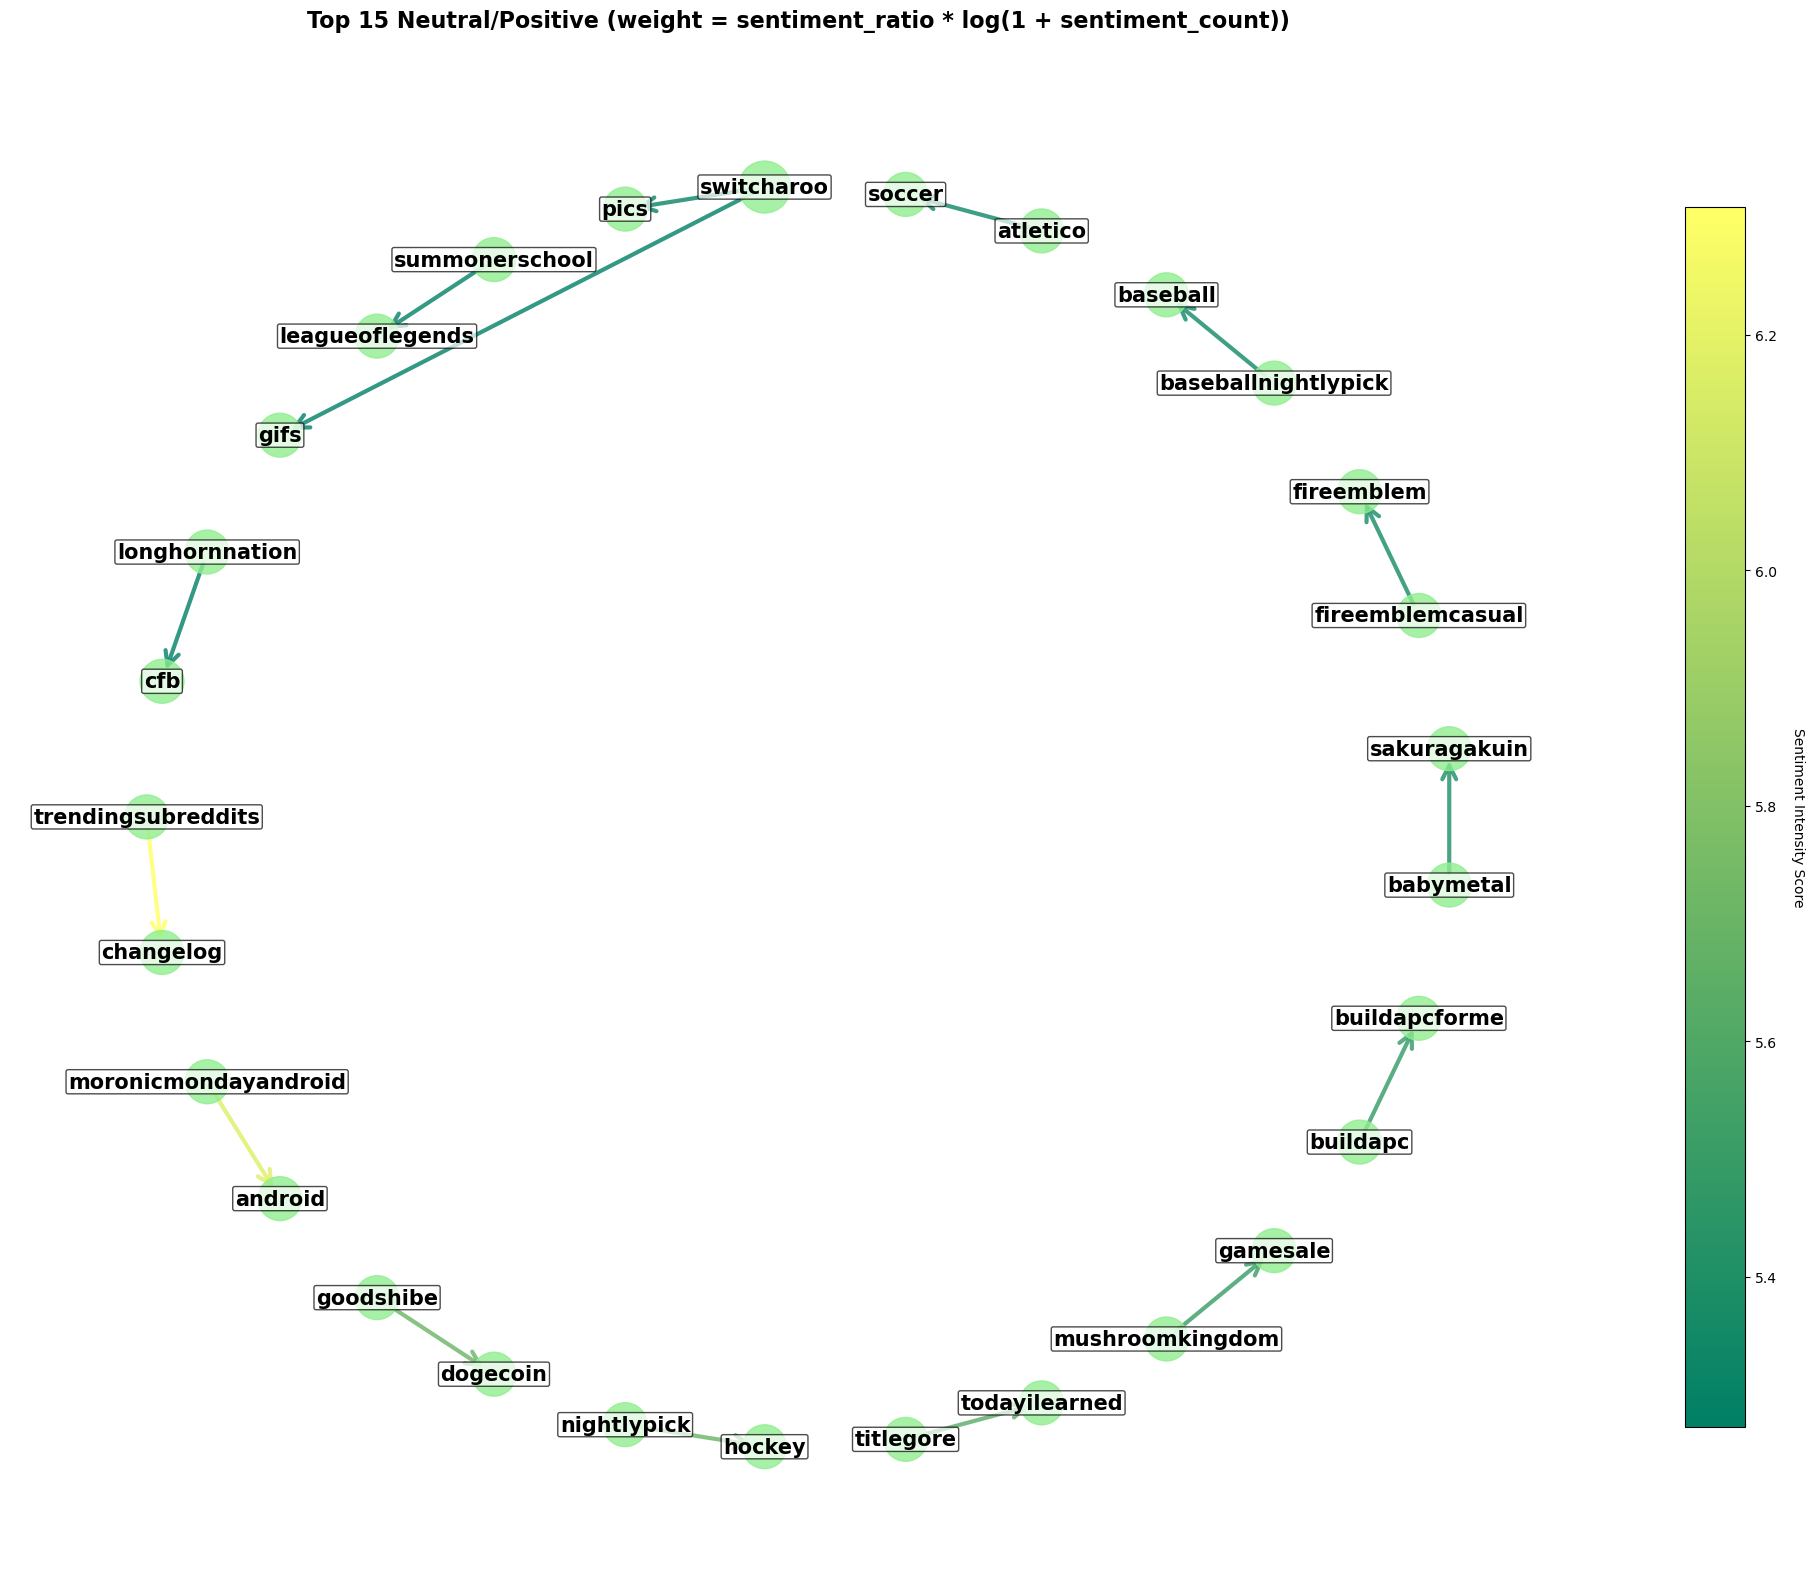

In [3]:
from src.analysis.sentiment_graphs.create_sentiment_graph import create_and_visualize_graph

# Note: 'sentiment_intensity' is the best metric to visualize imo

# NEGATIVE SENTIMENT
create_and_visualize_graph(G, 'sentiment_frequency', top_n=15, show=True)
create_and_visualize_graph(G, 'relative_sentiment', top_n=15, show=True)
create_and_visualize_graph(G, 'sentiment_intensity', sentiment='neg', top_n=15, show=True)
create_and_visualize_graph(G, 'sentiment_count', top_n=15, show=True)
create_and_visualize_graph(G, 'source_total_sentiment', top_n=15, show=True)
create_and_visualize_graph(G, 'source_activity_weighted', top_n=15, show=True)
create_and_visualize_graph(G, 'target_activity_weighted', top_n=15, show=True)
create_and_visualize_graph(G, 'combined_activity', top_n=15, show=True)
create_and_visualize_graph(G, 'subreddit_size_ratio', top_n=15, show=True)

# POSITIVE SENTIMENT
create_and_visualize_graph(G, 'sentiment_intensity', sentiment='pos', top_n=15, show=True)

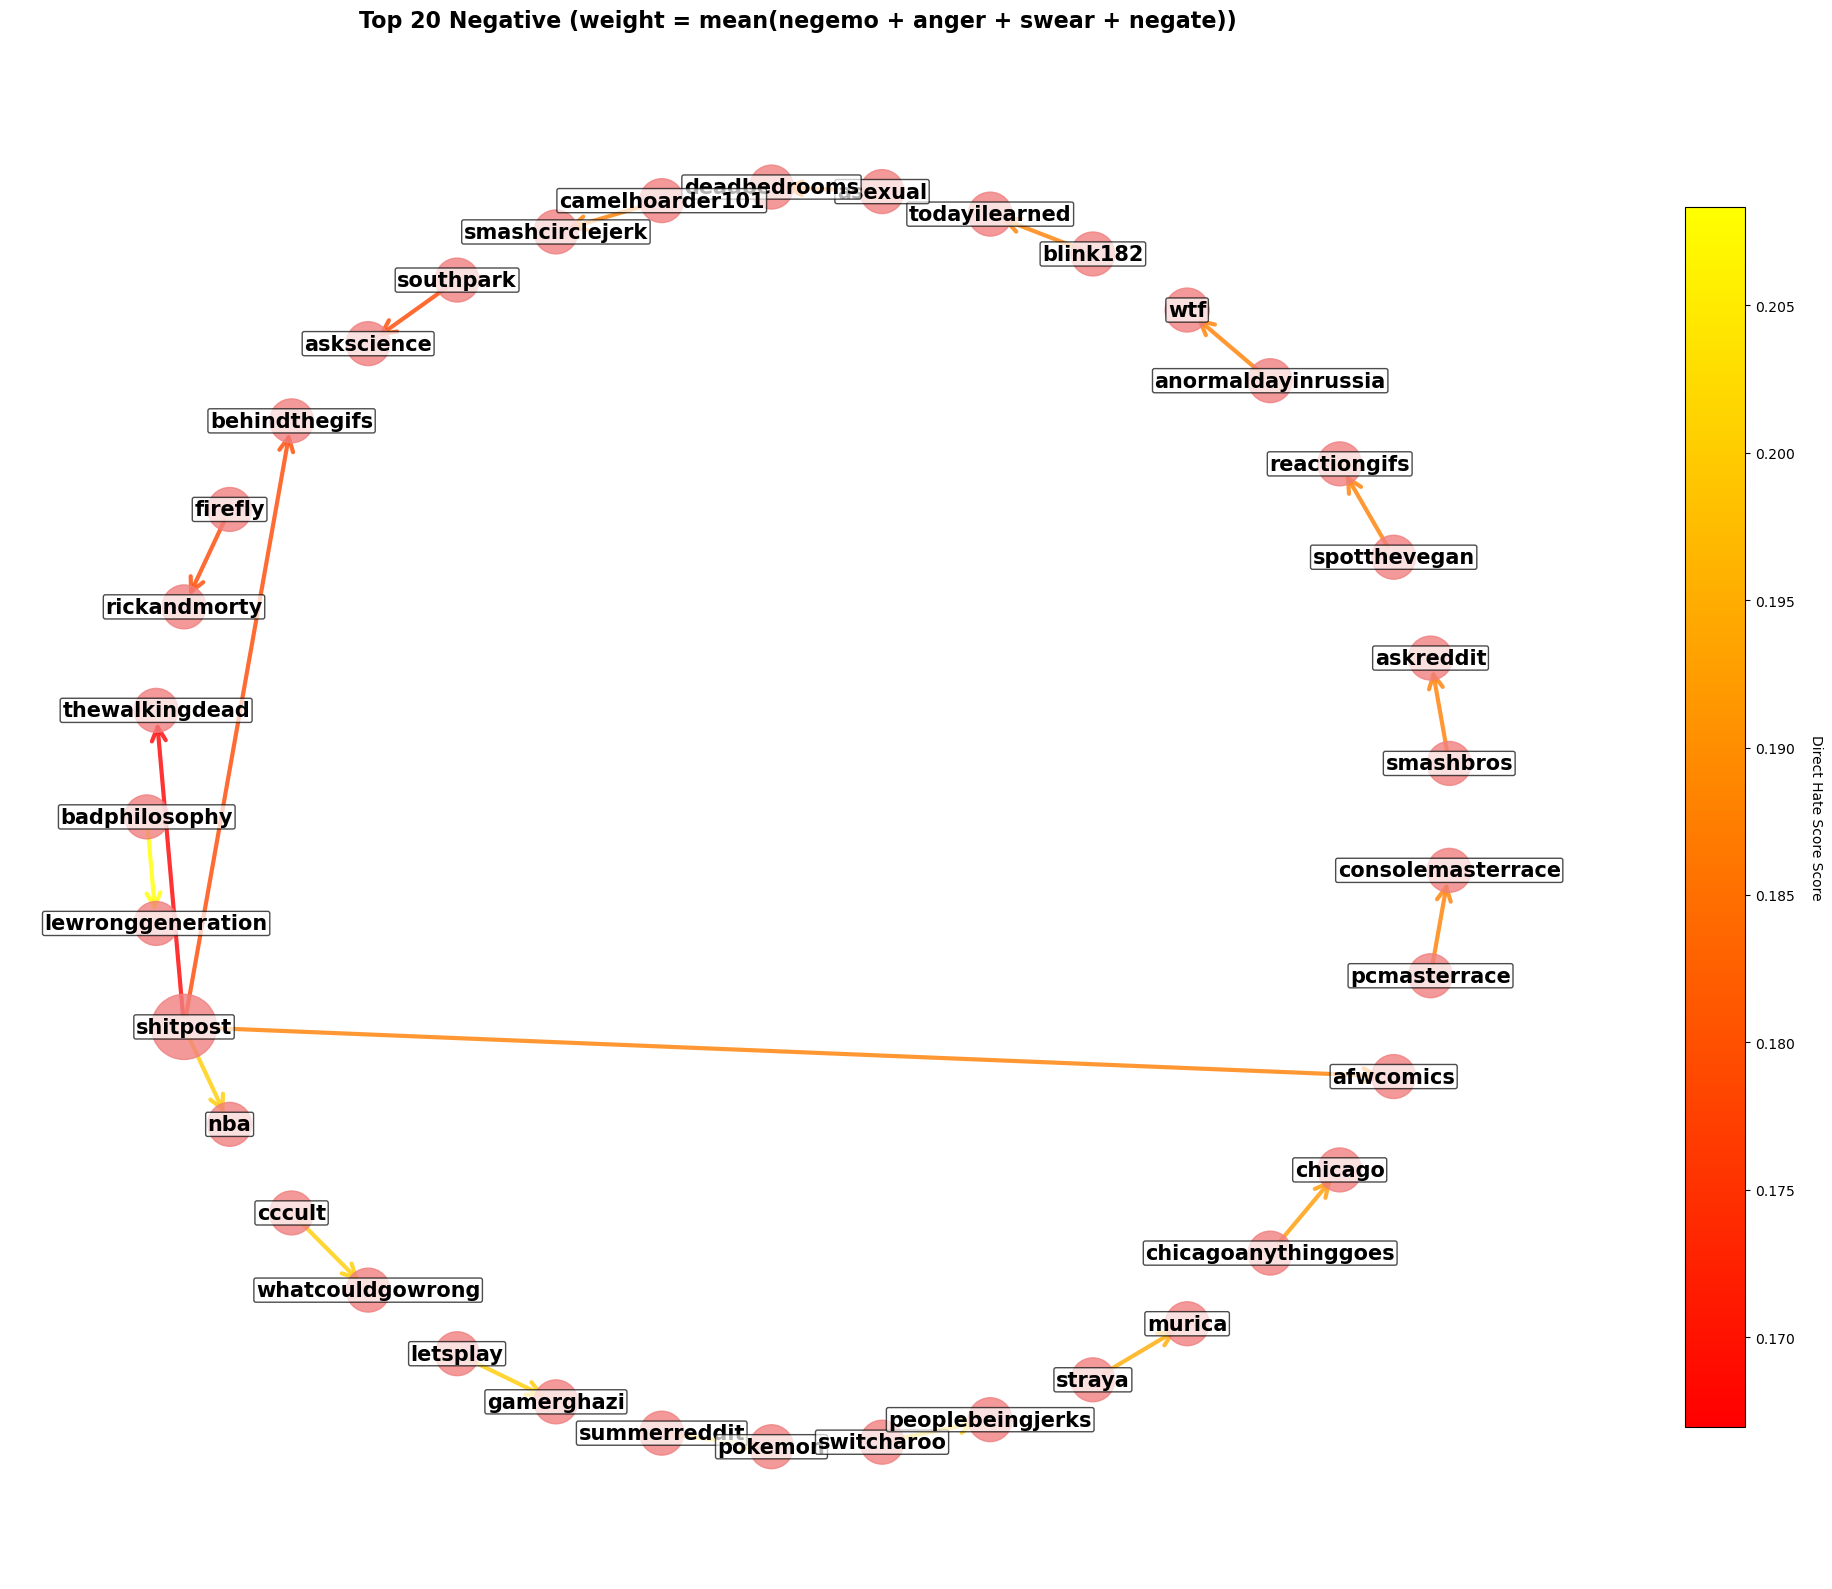

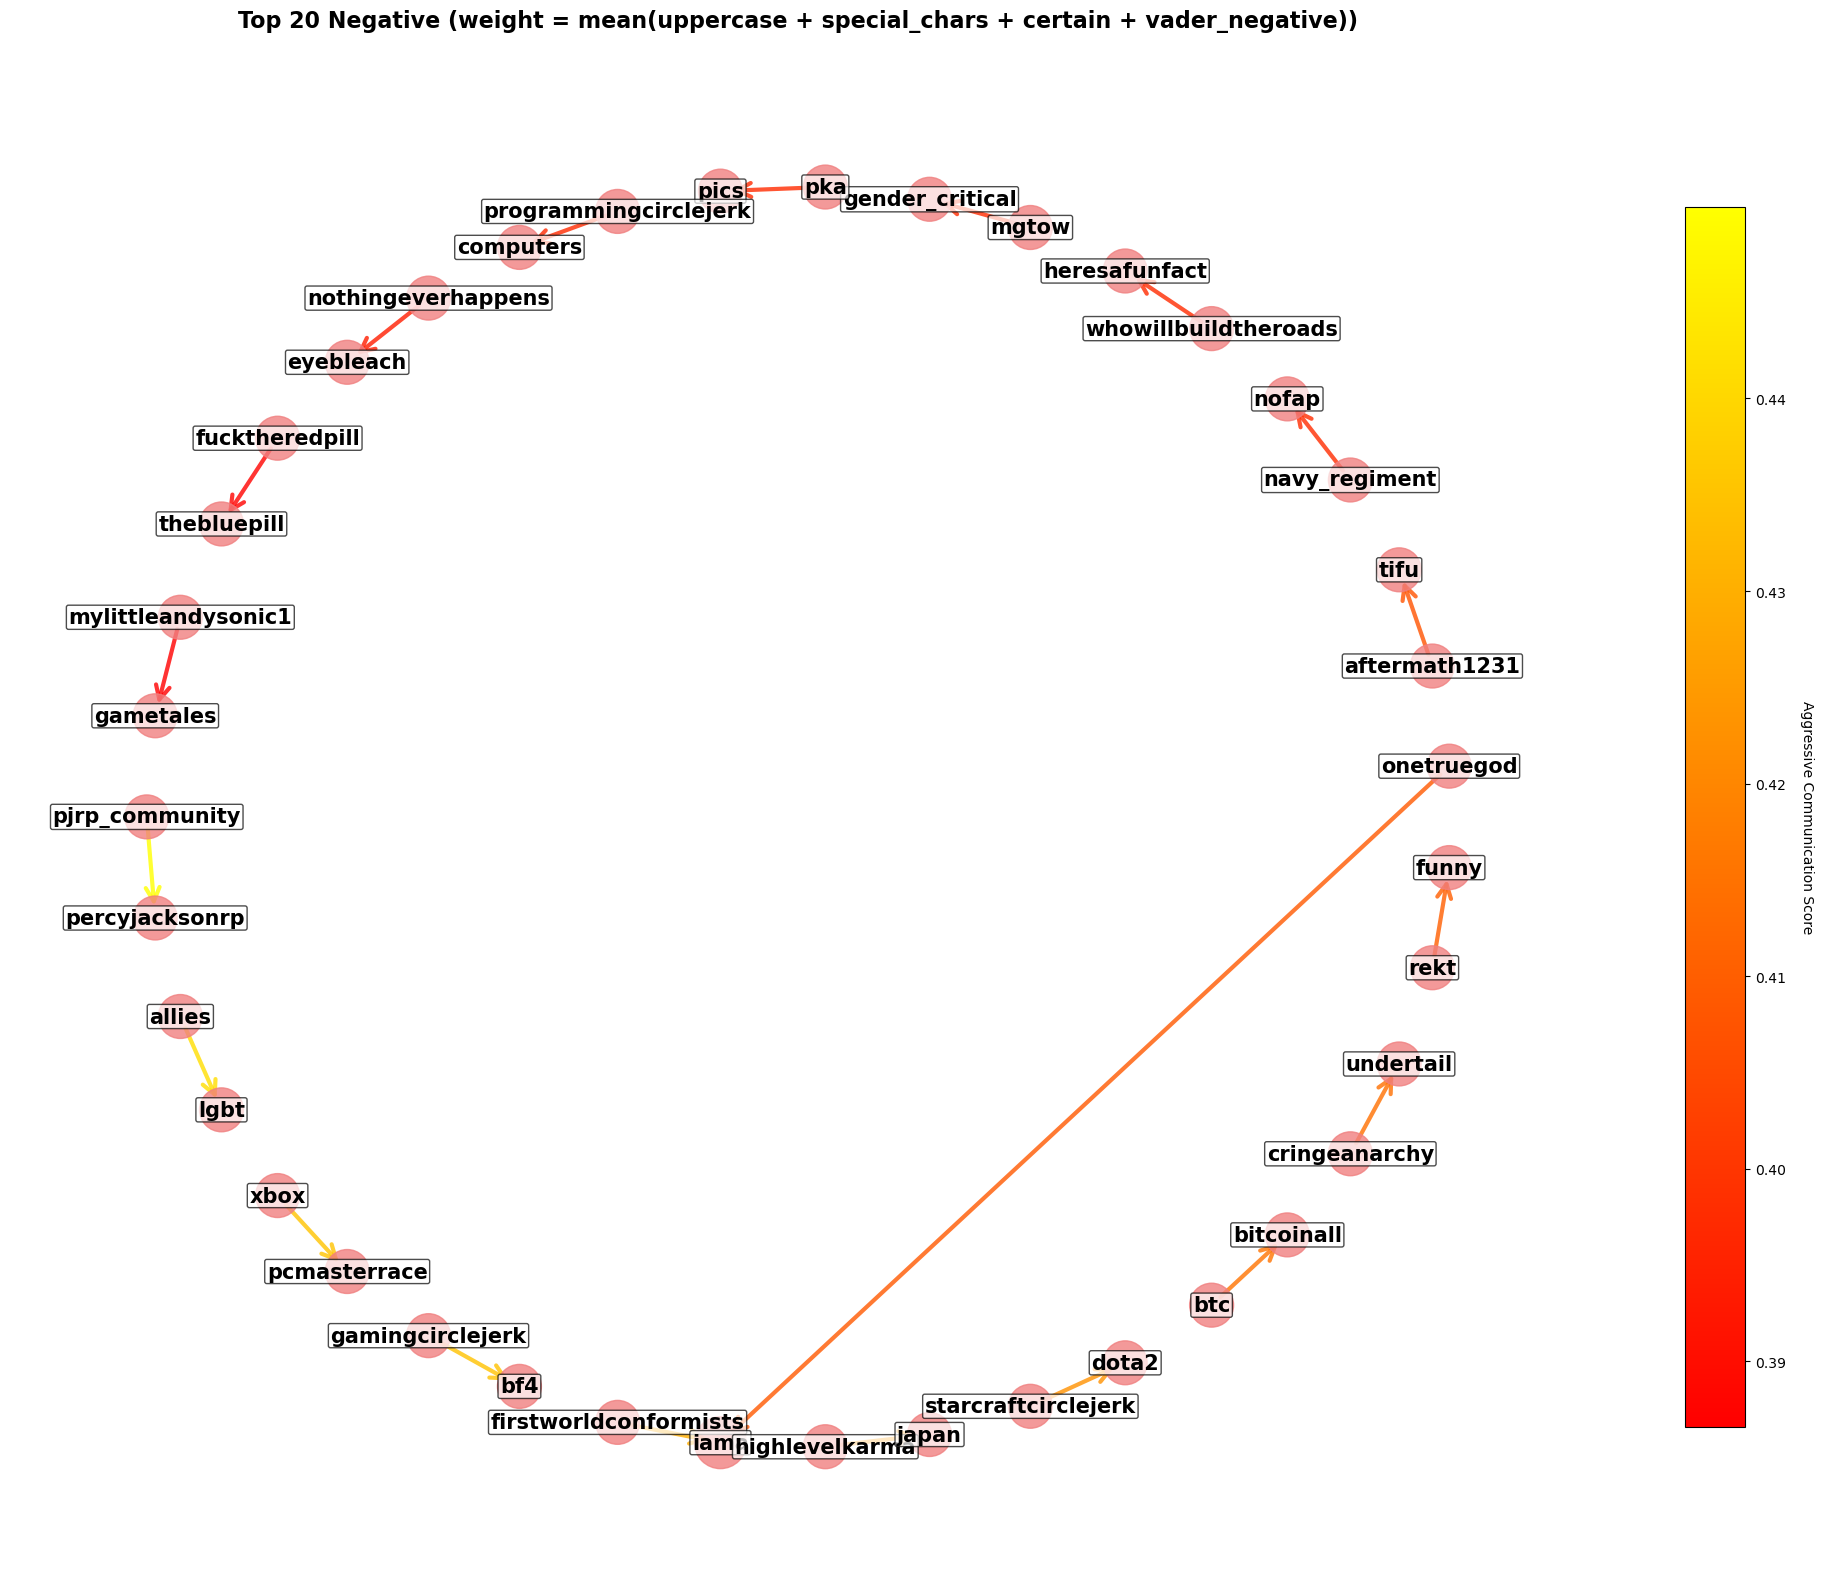

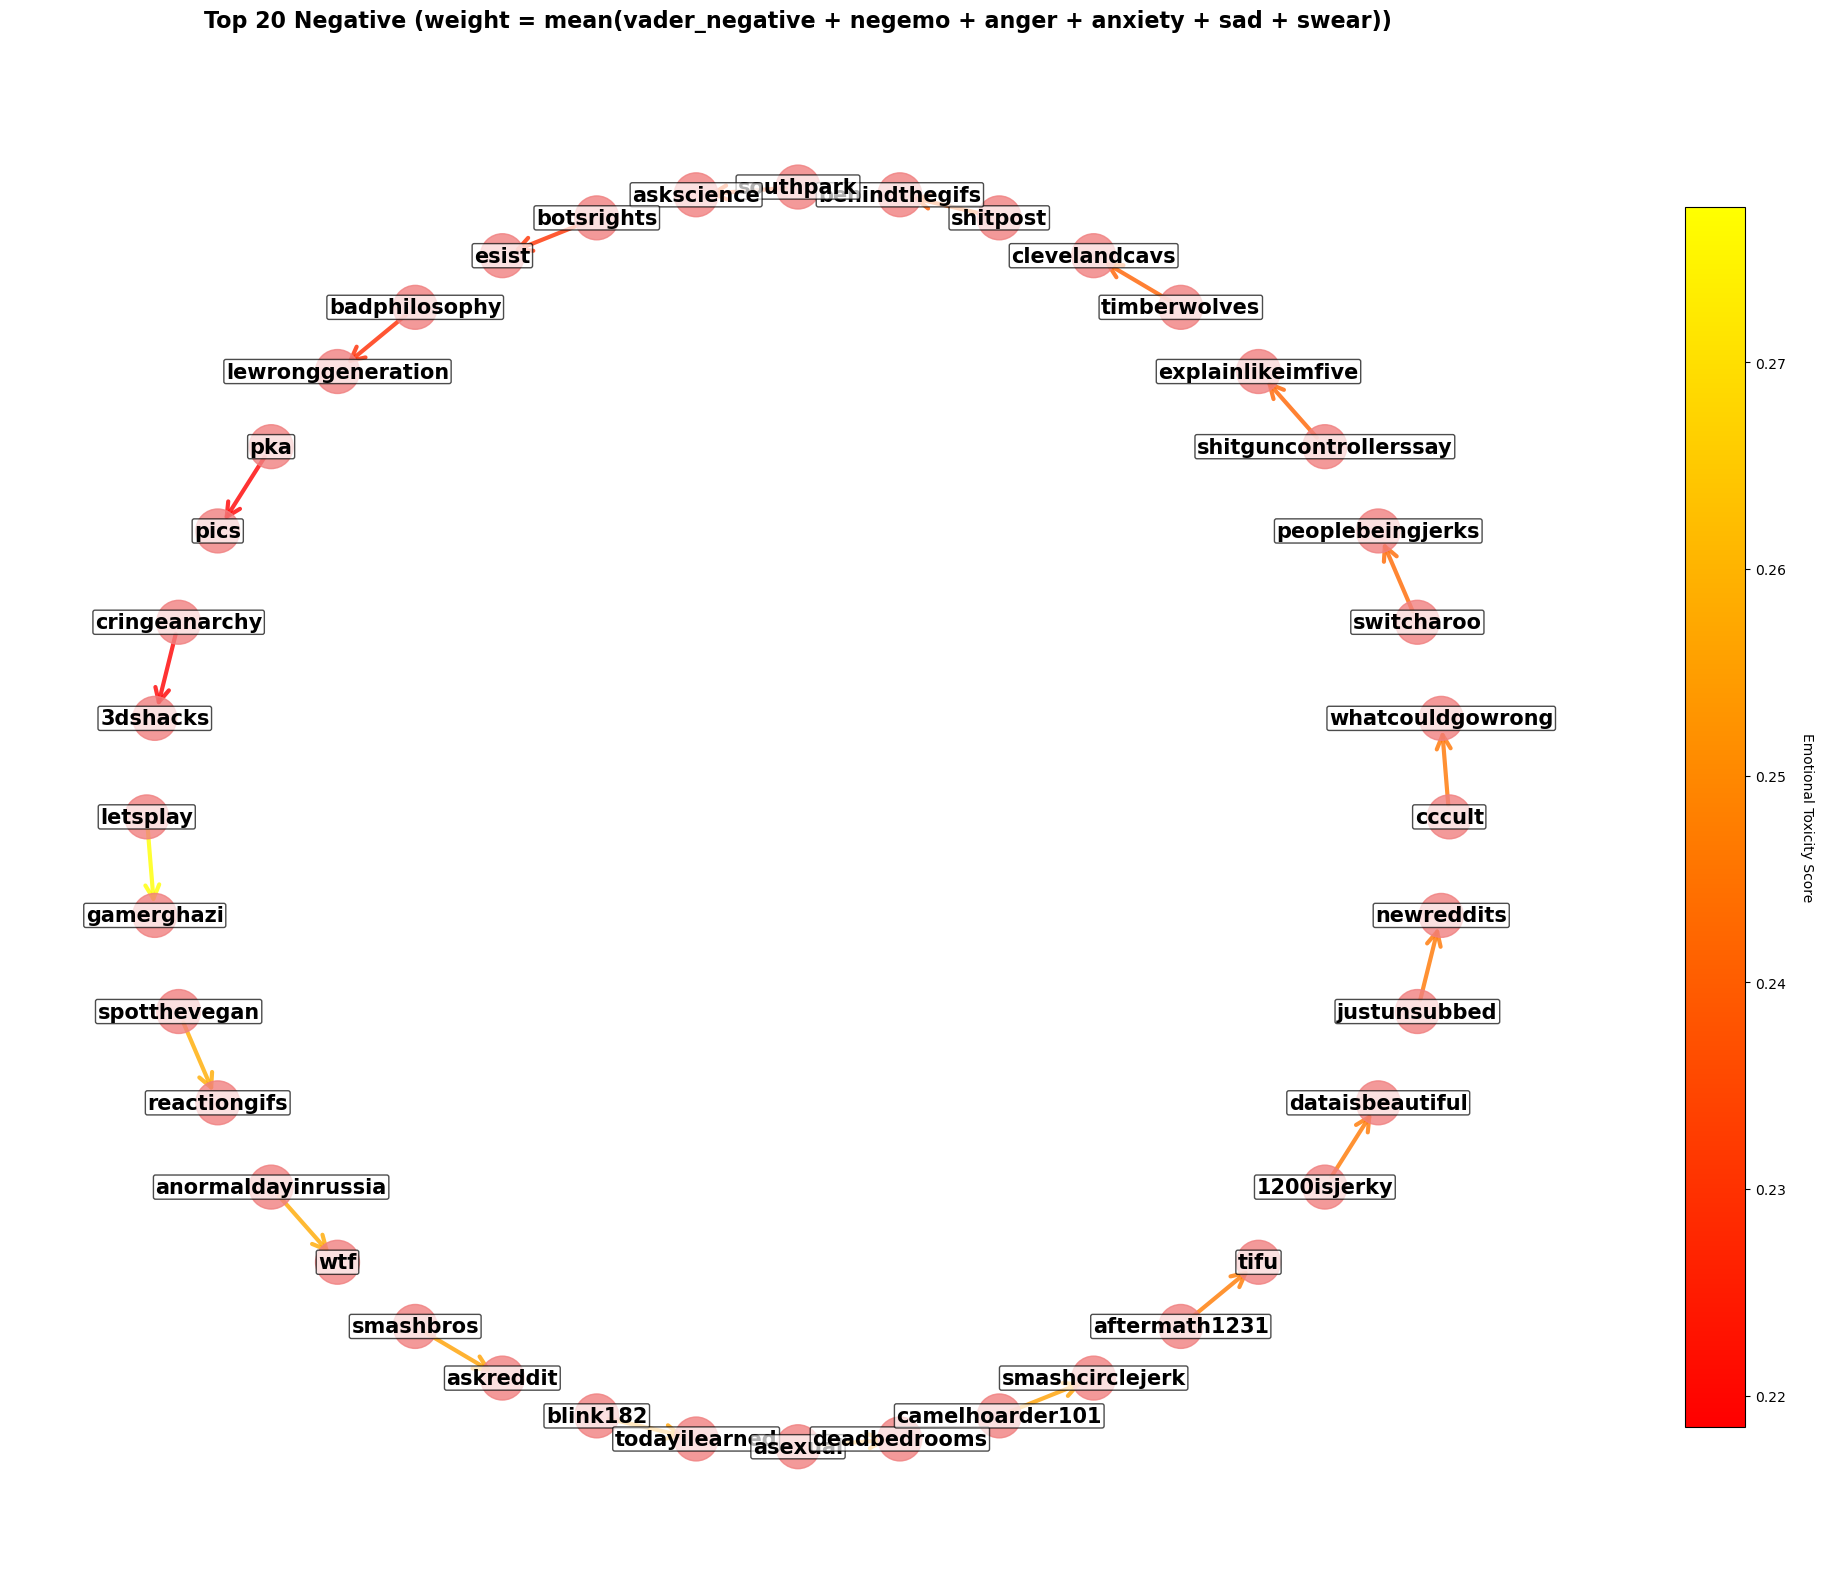

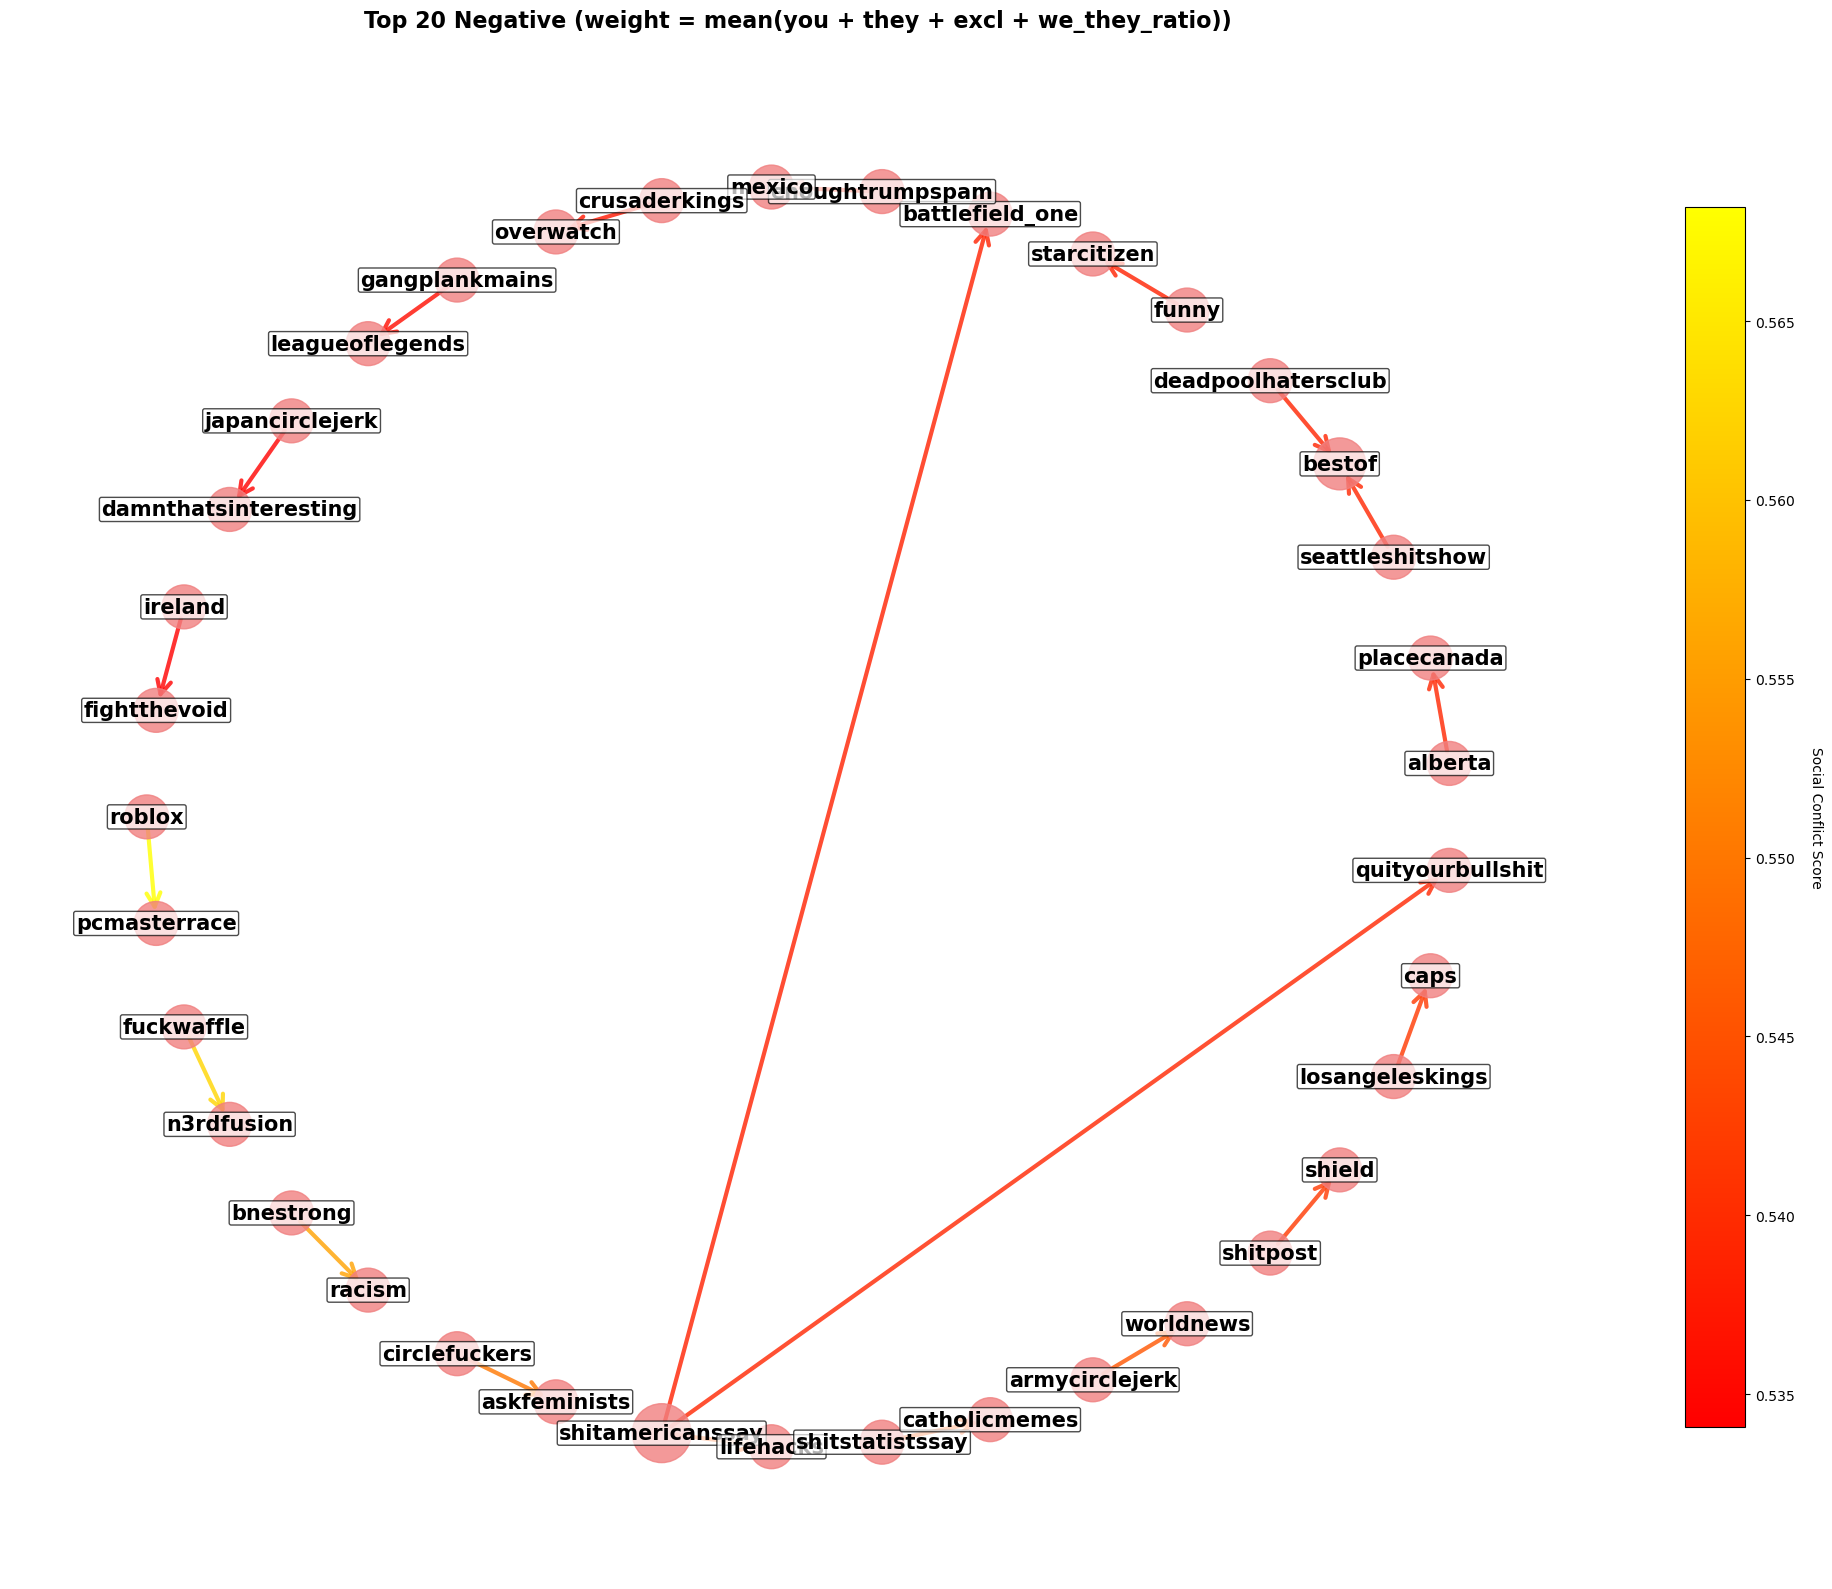

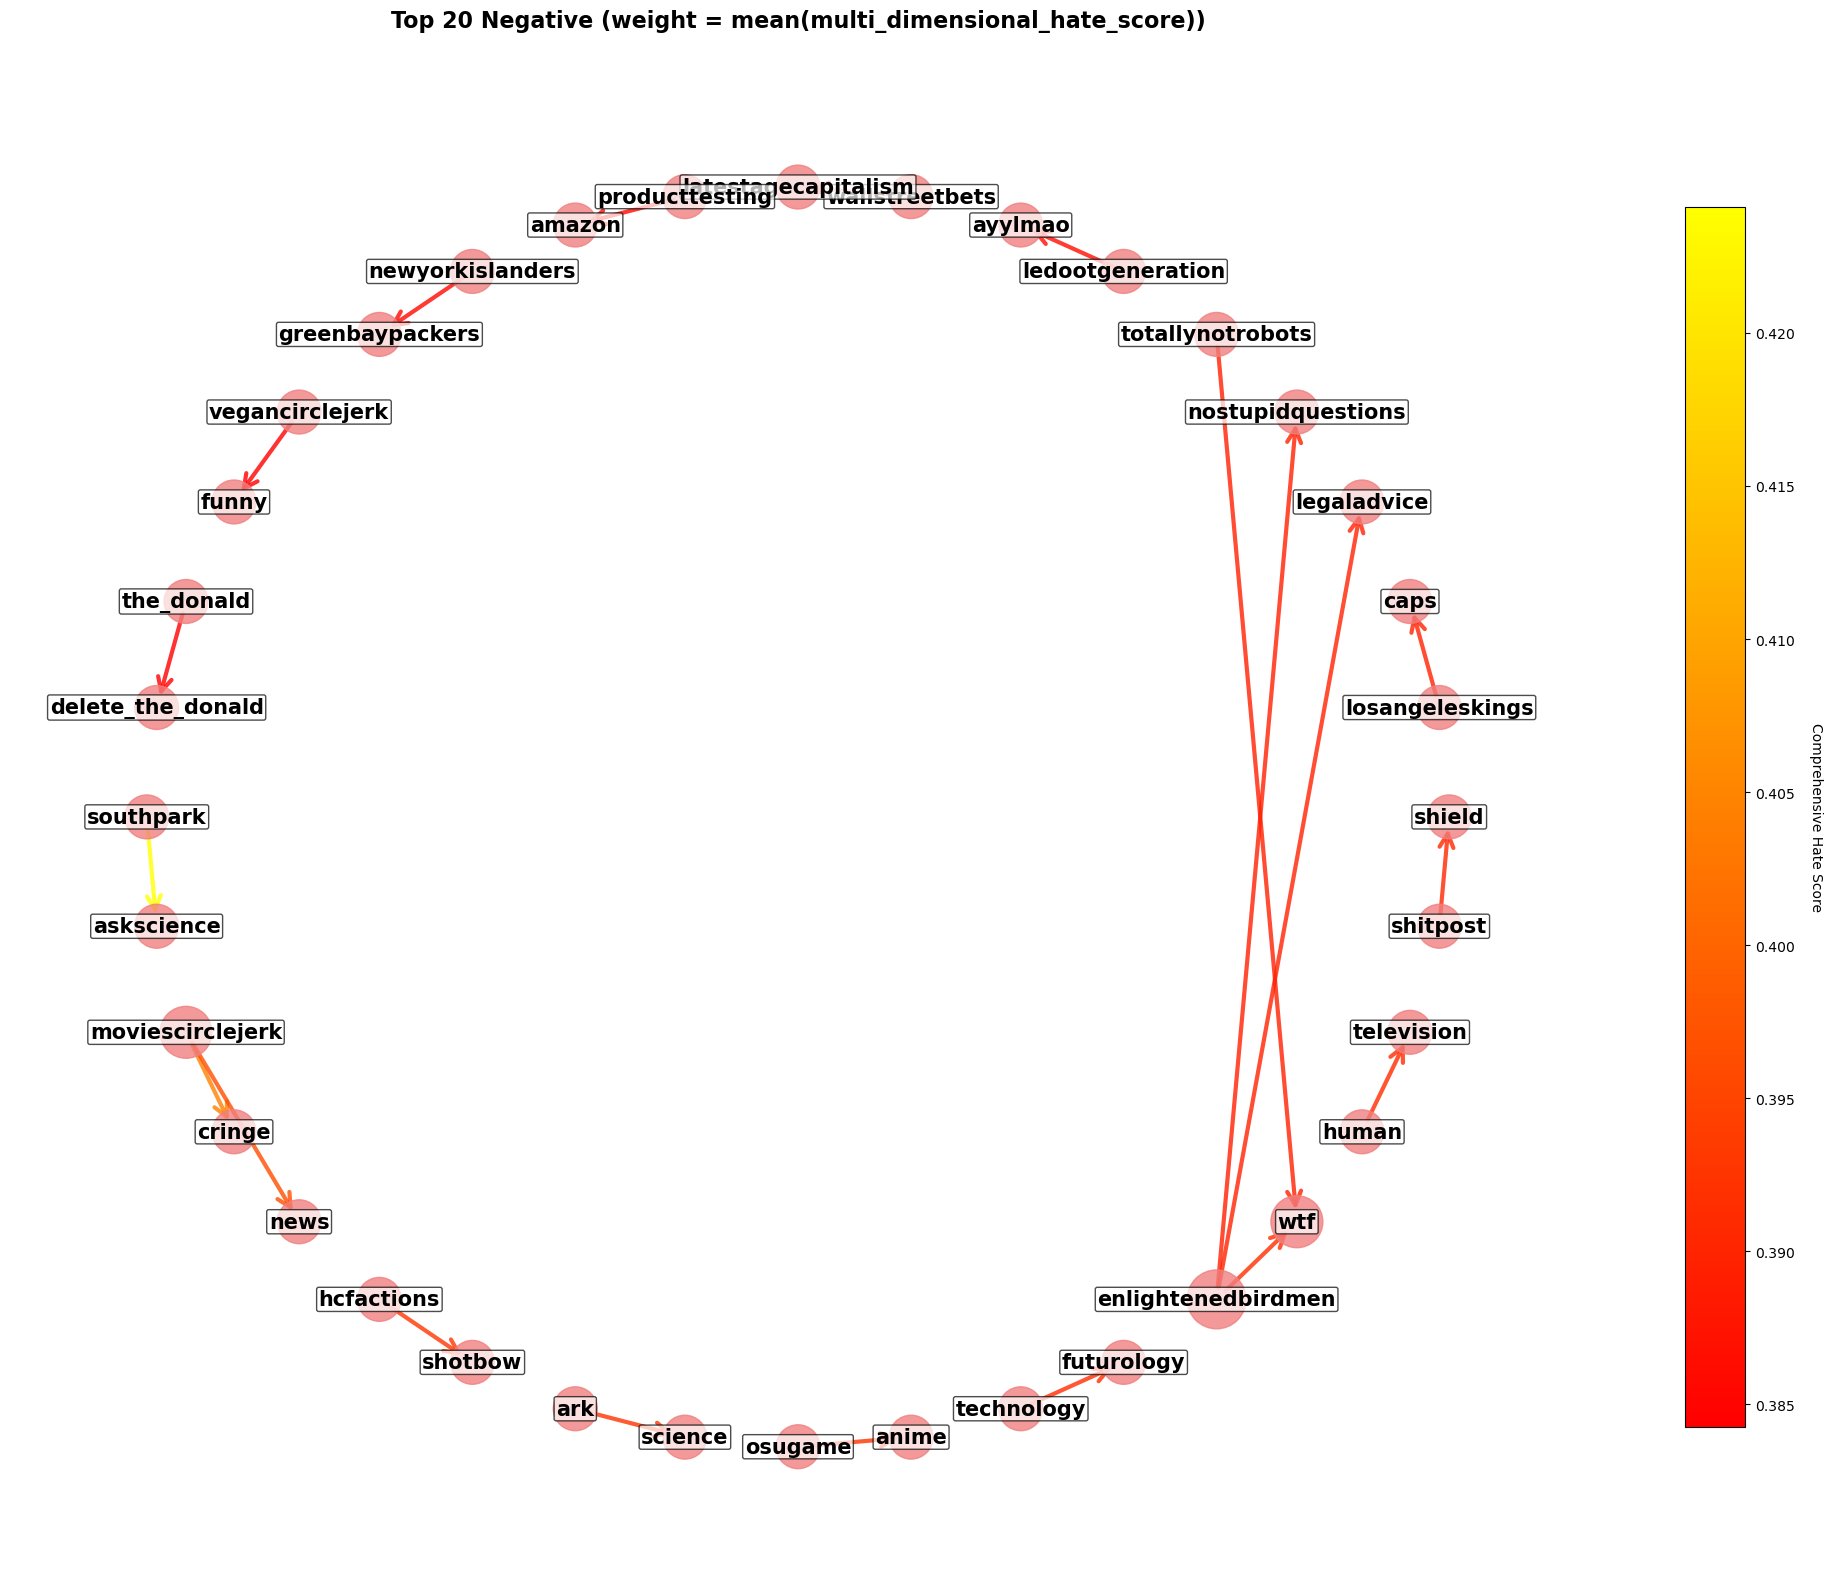

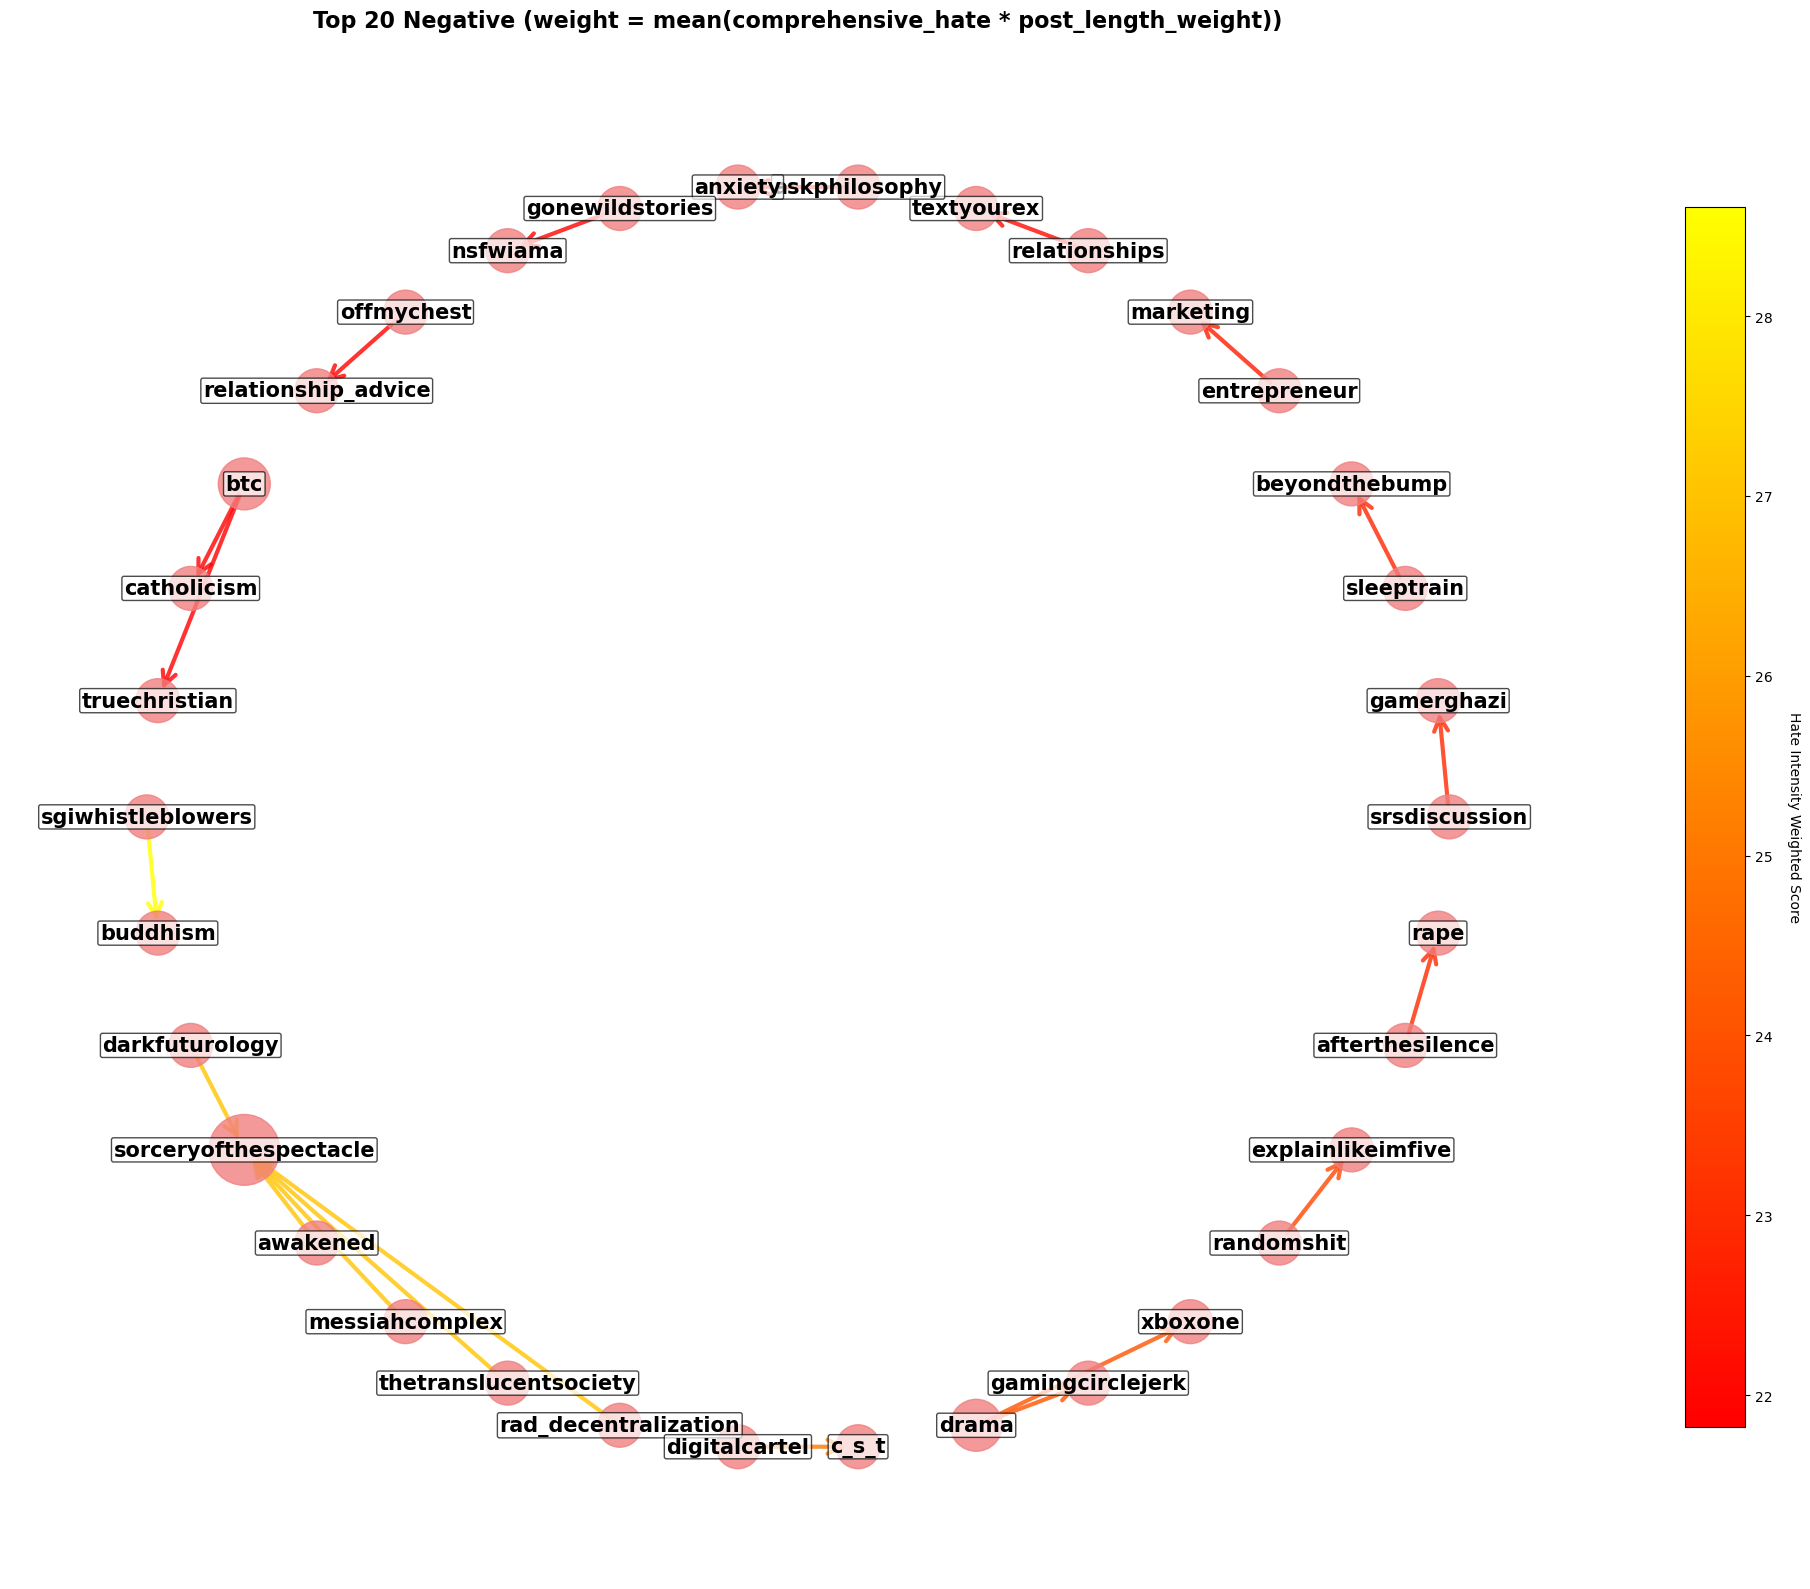

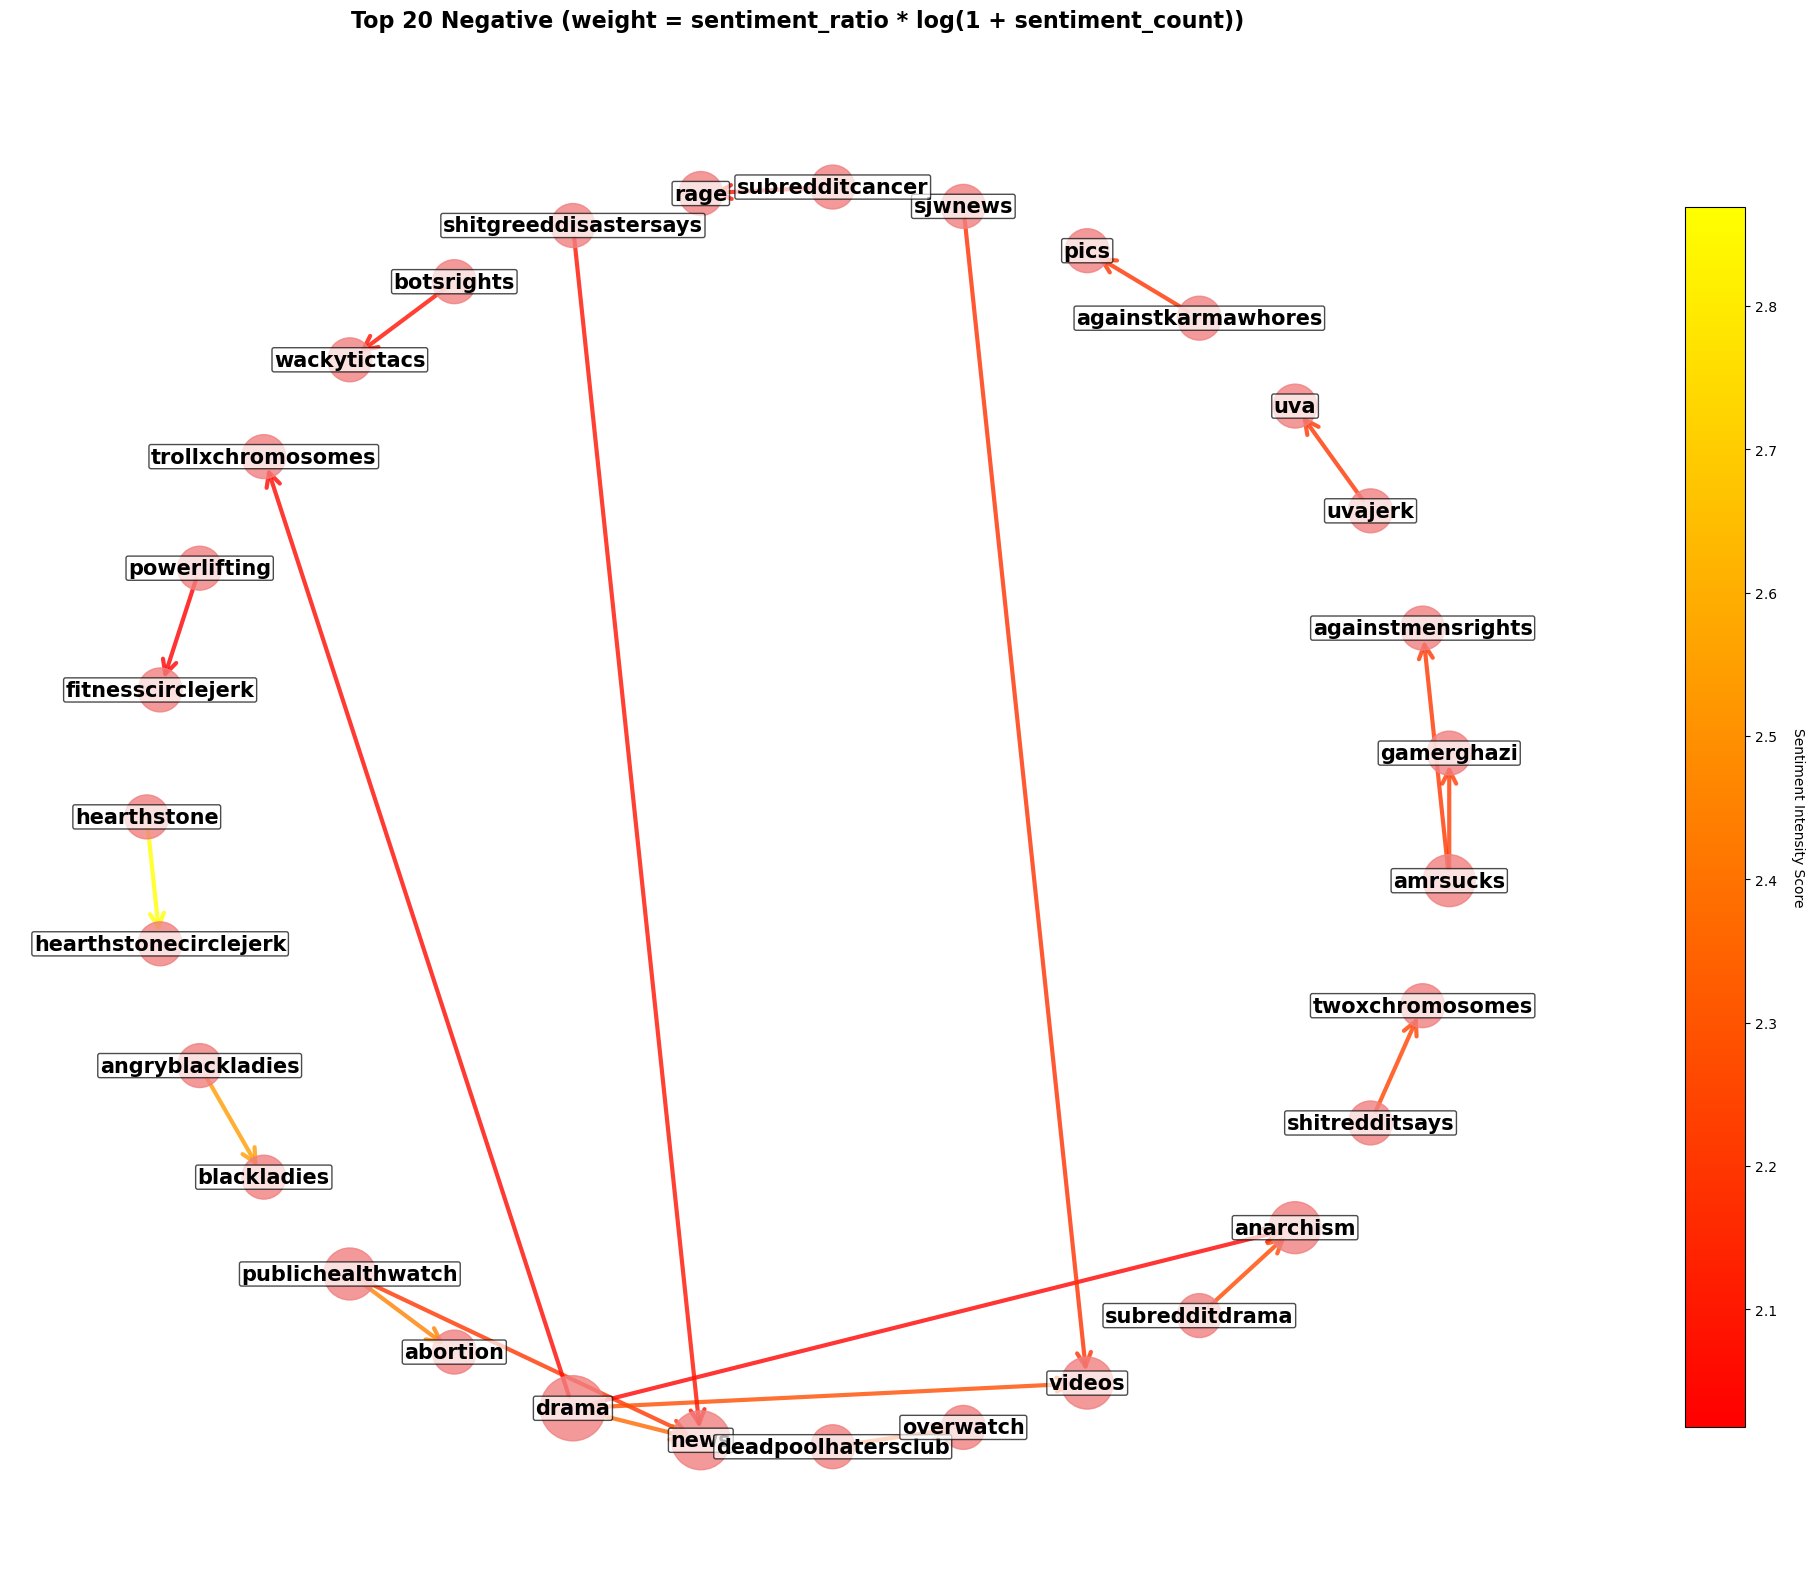

In [4]:
from src.analysis.sentiment_graphs.create_sentiment_graph import create_and_visualize_graph

# The second metric is the most descriptive imo

create_and_visualize_graph(G, 'direct_hate_score', sentiment='neg', top_n=20, show=True)
create_and_visualize_graph(G, 'aggressive_communication', sentiment='neg', top_n=20, show=True)
create_and_visualize_graph(G, 'emotional_toxicity', sentiment='neg', top_n=20, show=True)
create_and_visualize_graph(G, 'social_conflict', sentiment='neg', top_n=20, show=True)
create_and_visualize_graph(G, 'comprehensive_hate', sentiment='neg', top_n=20, show=True)
create_and_visualize_graph(G, 'hate_intensity_weighted', sentiment='neg', top_n=20, show=True)
create_and_visualize_graph(G, 'sentiment_intensity', sentiment='neg', top_n=20, show=True)

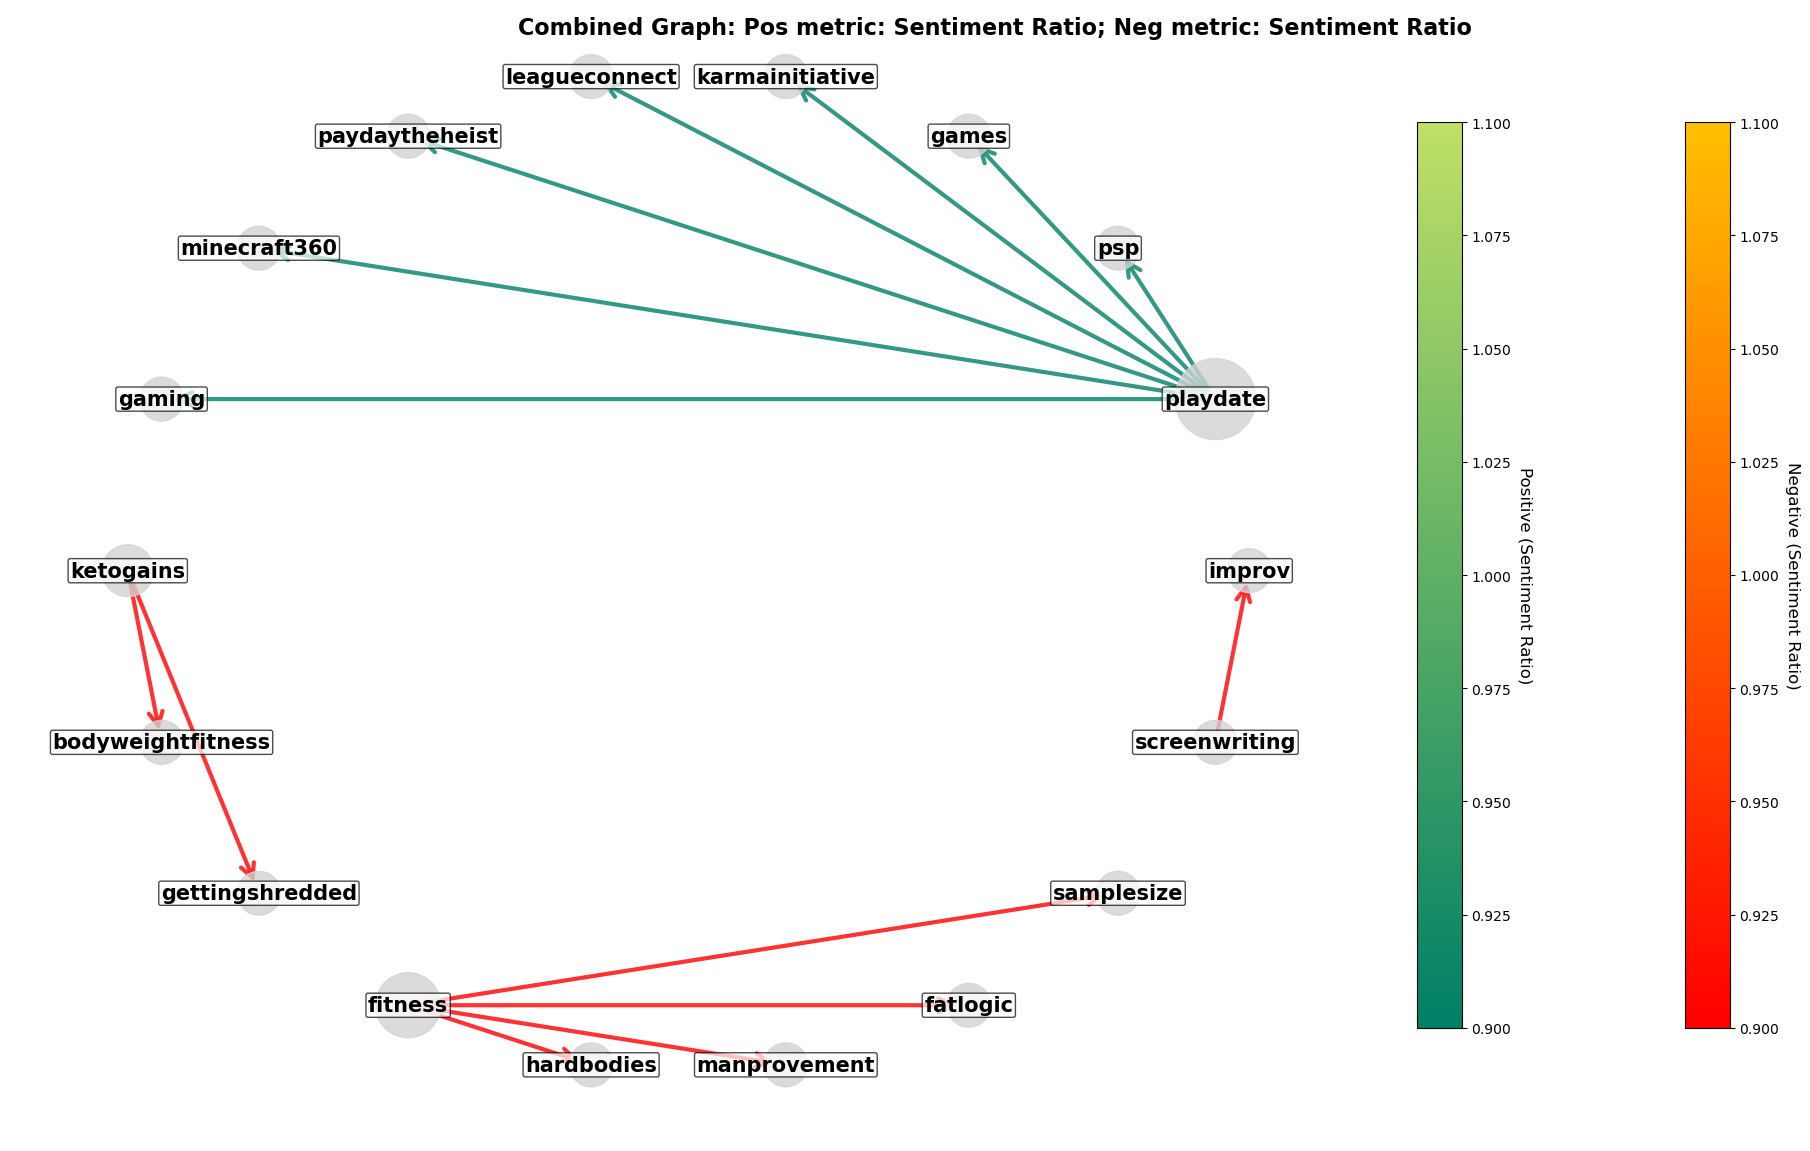

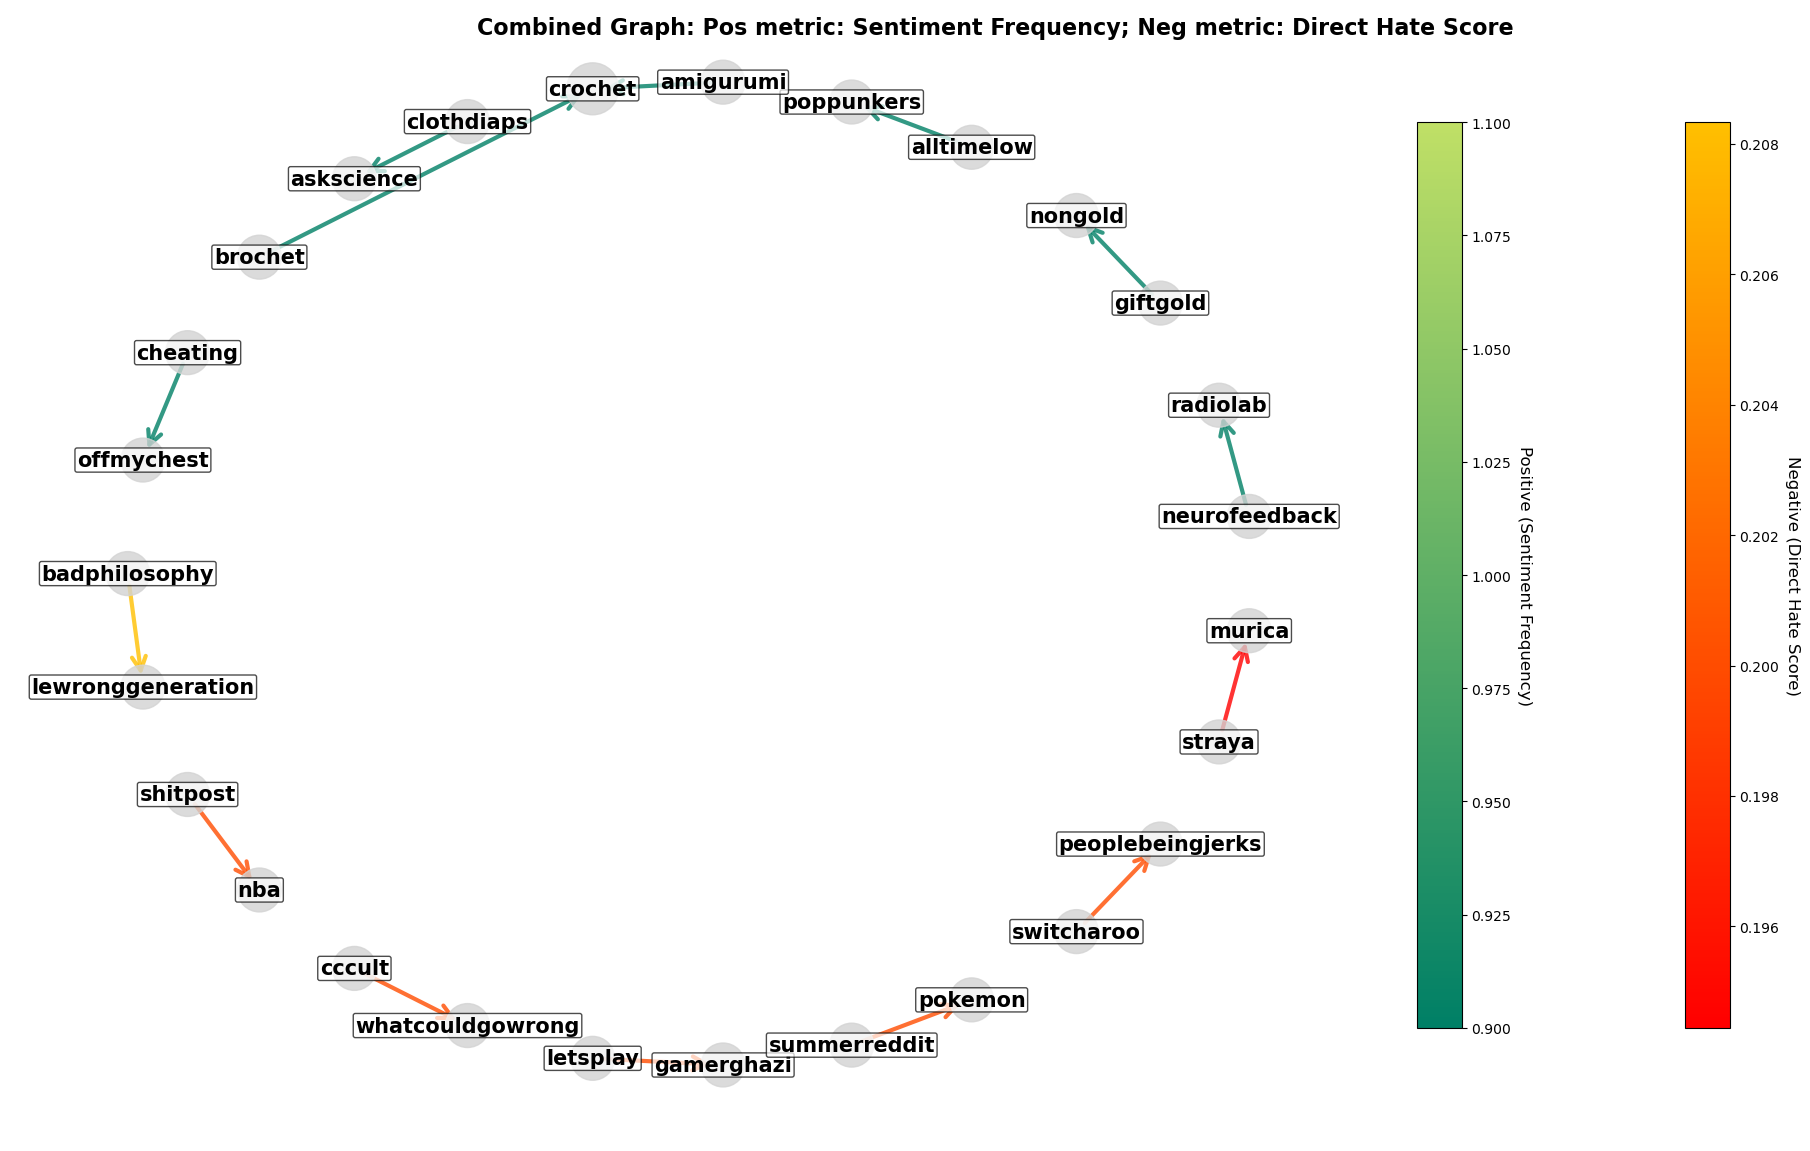

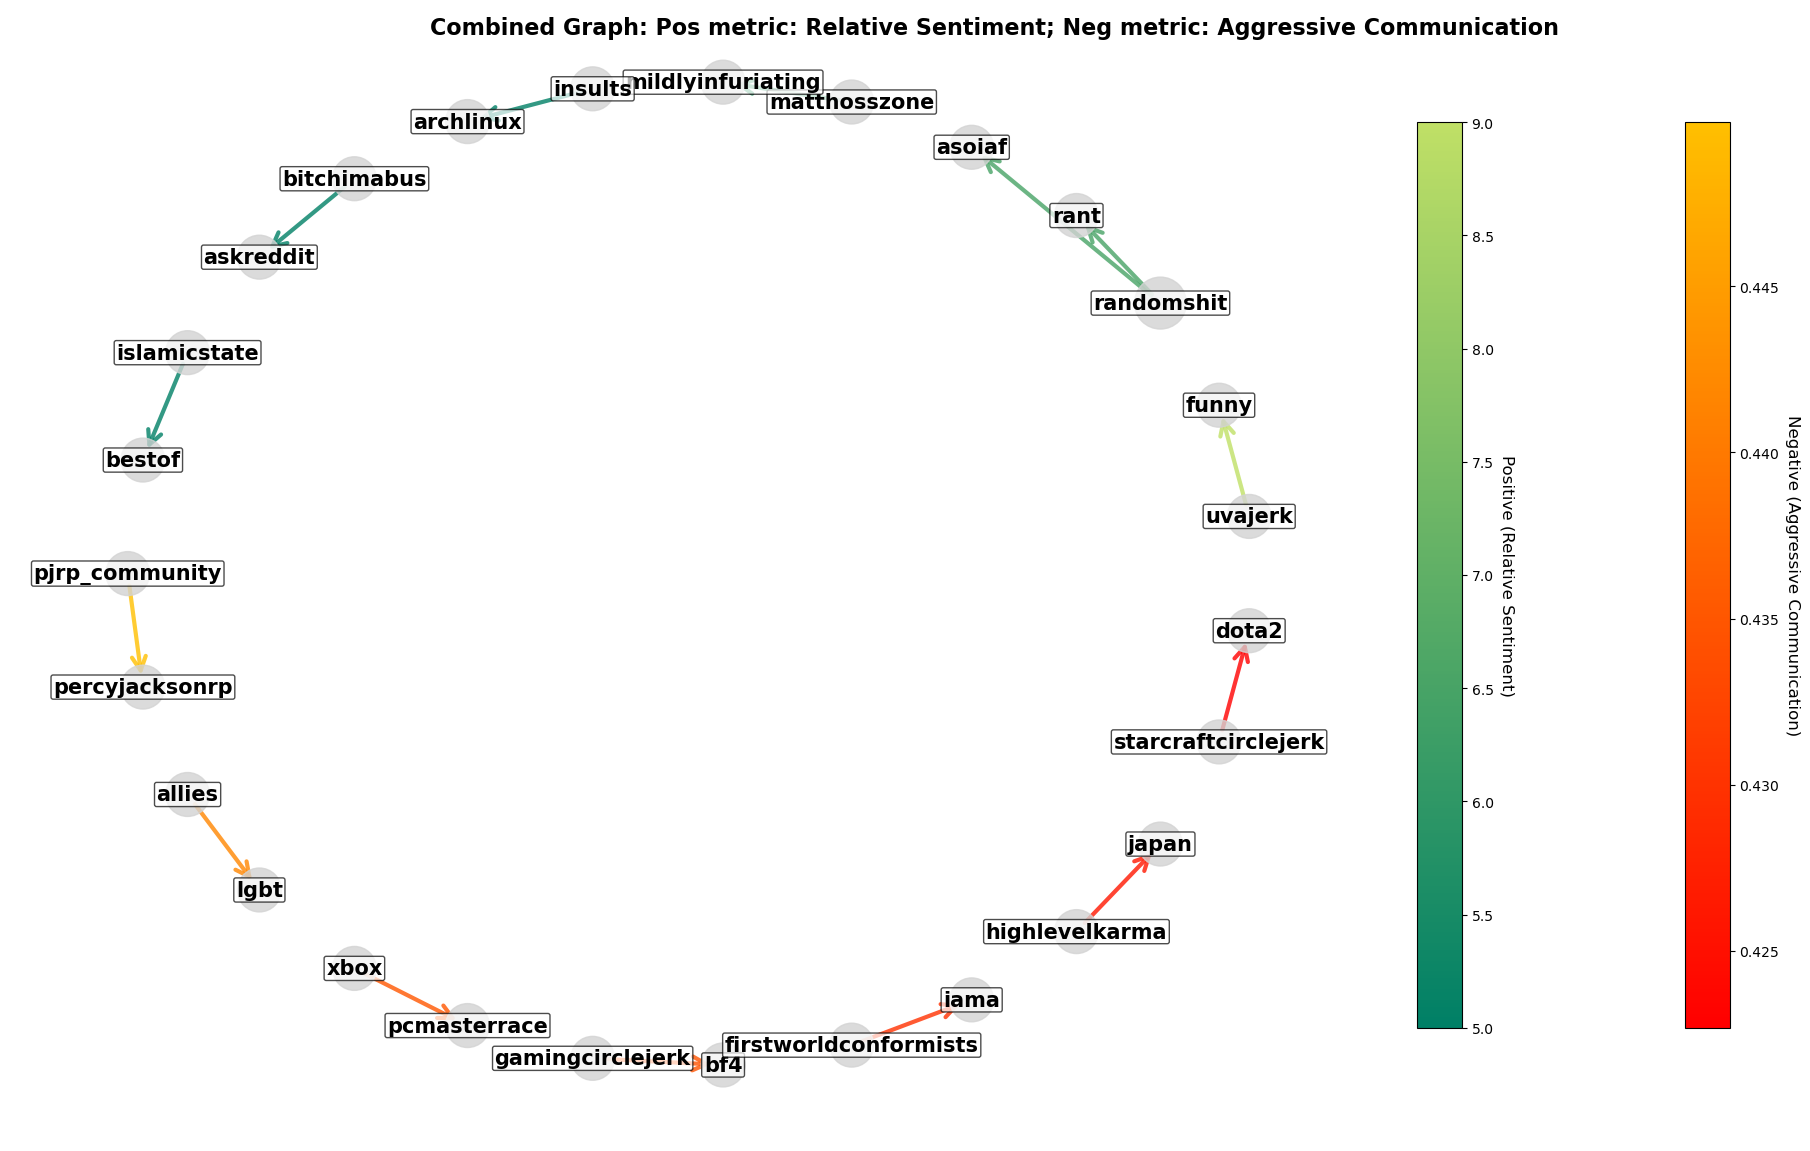

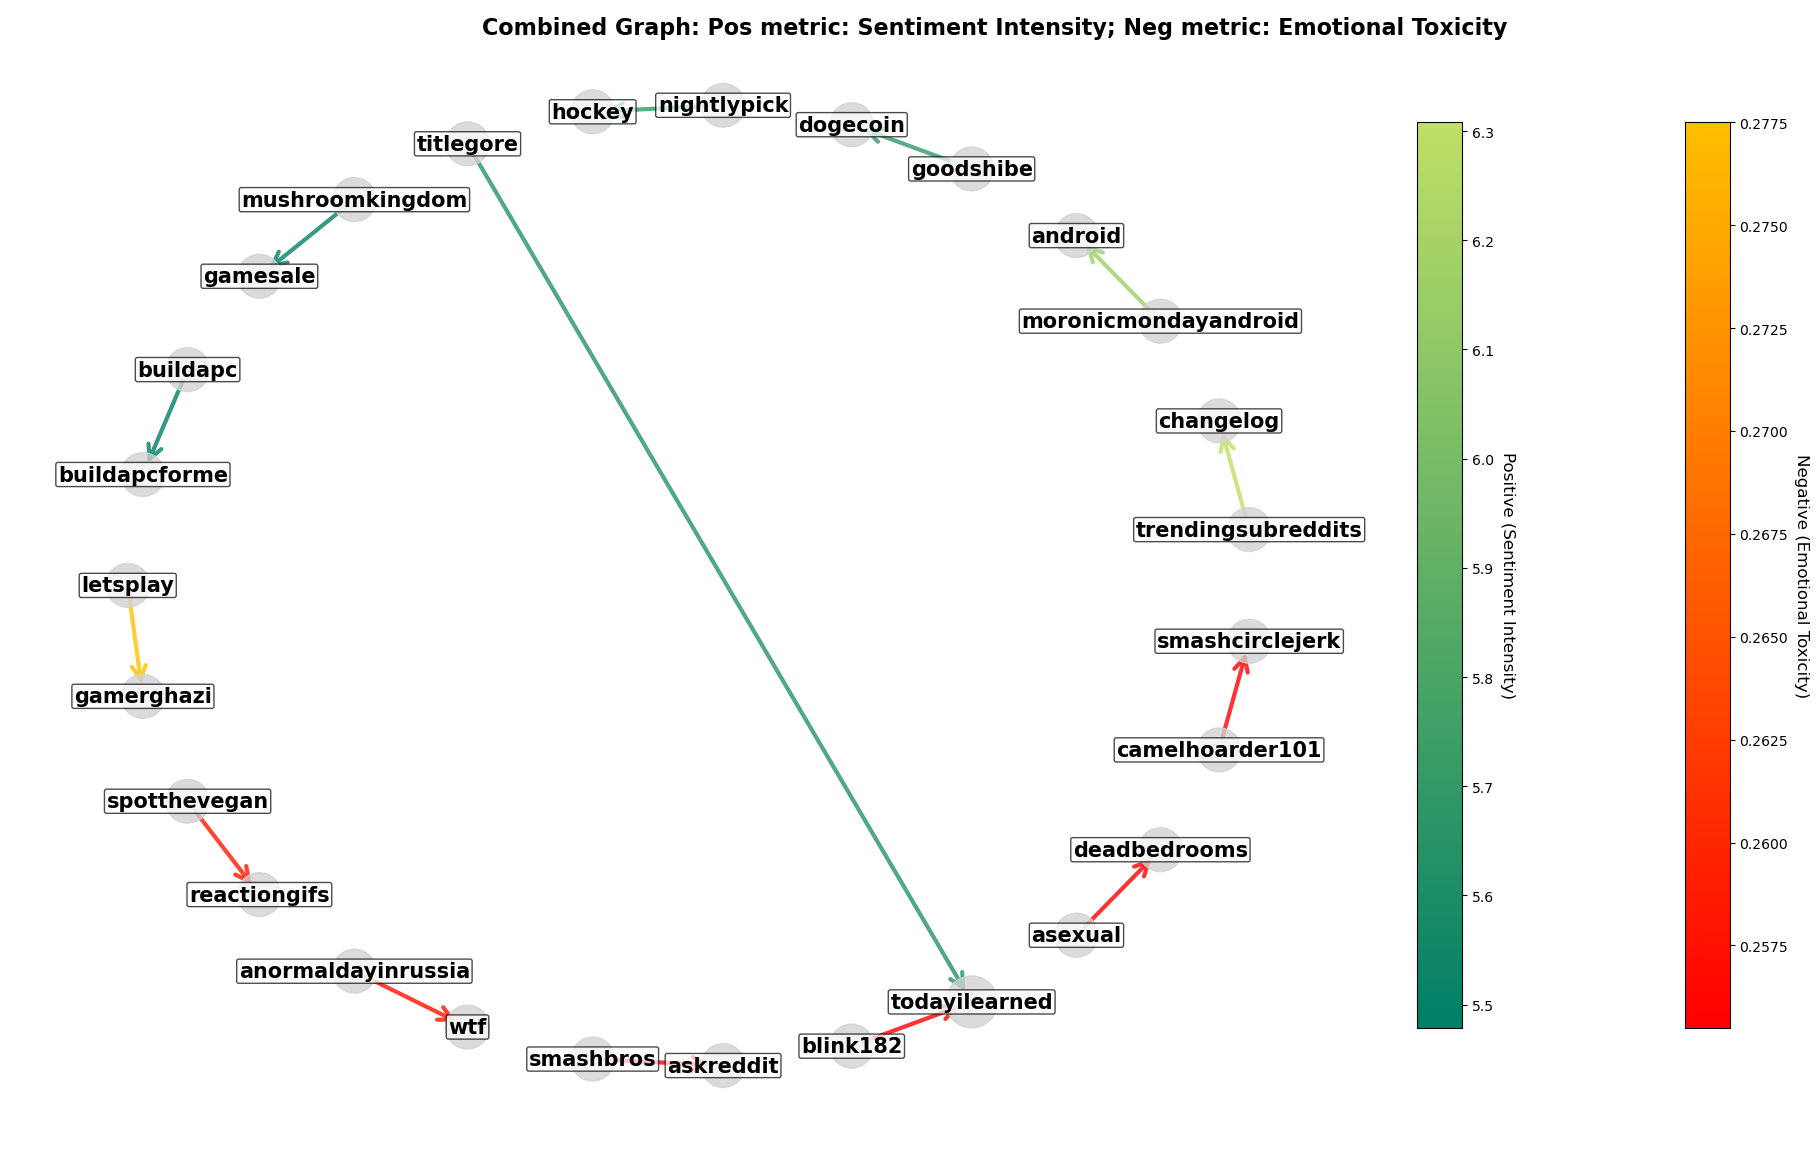

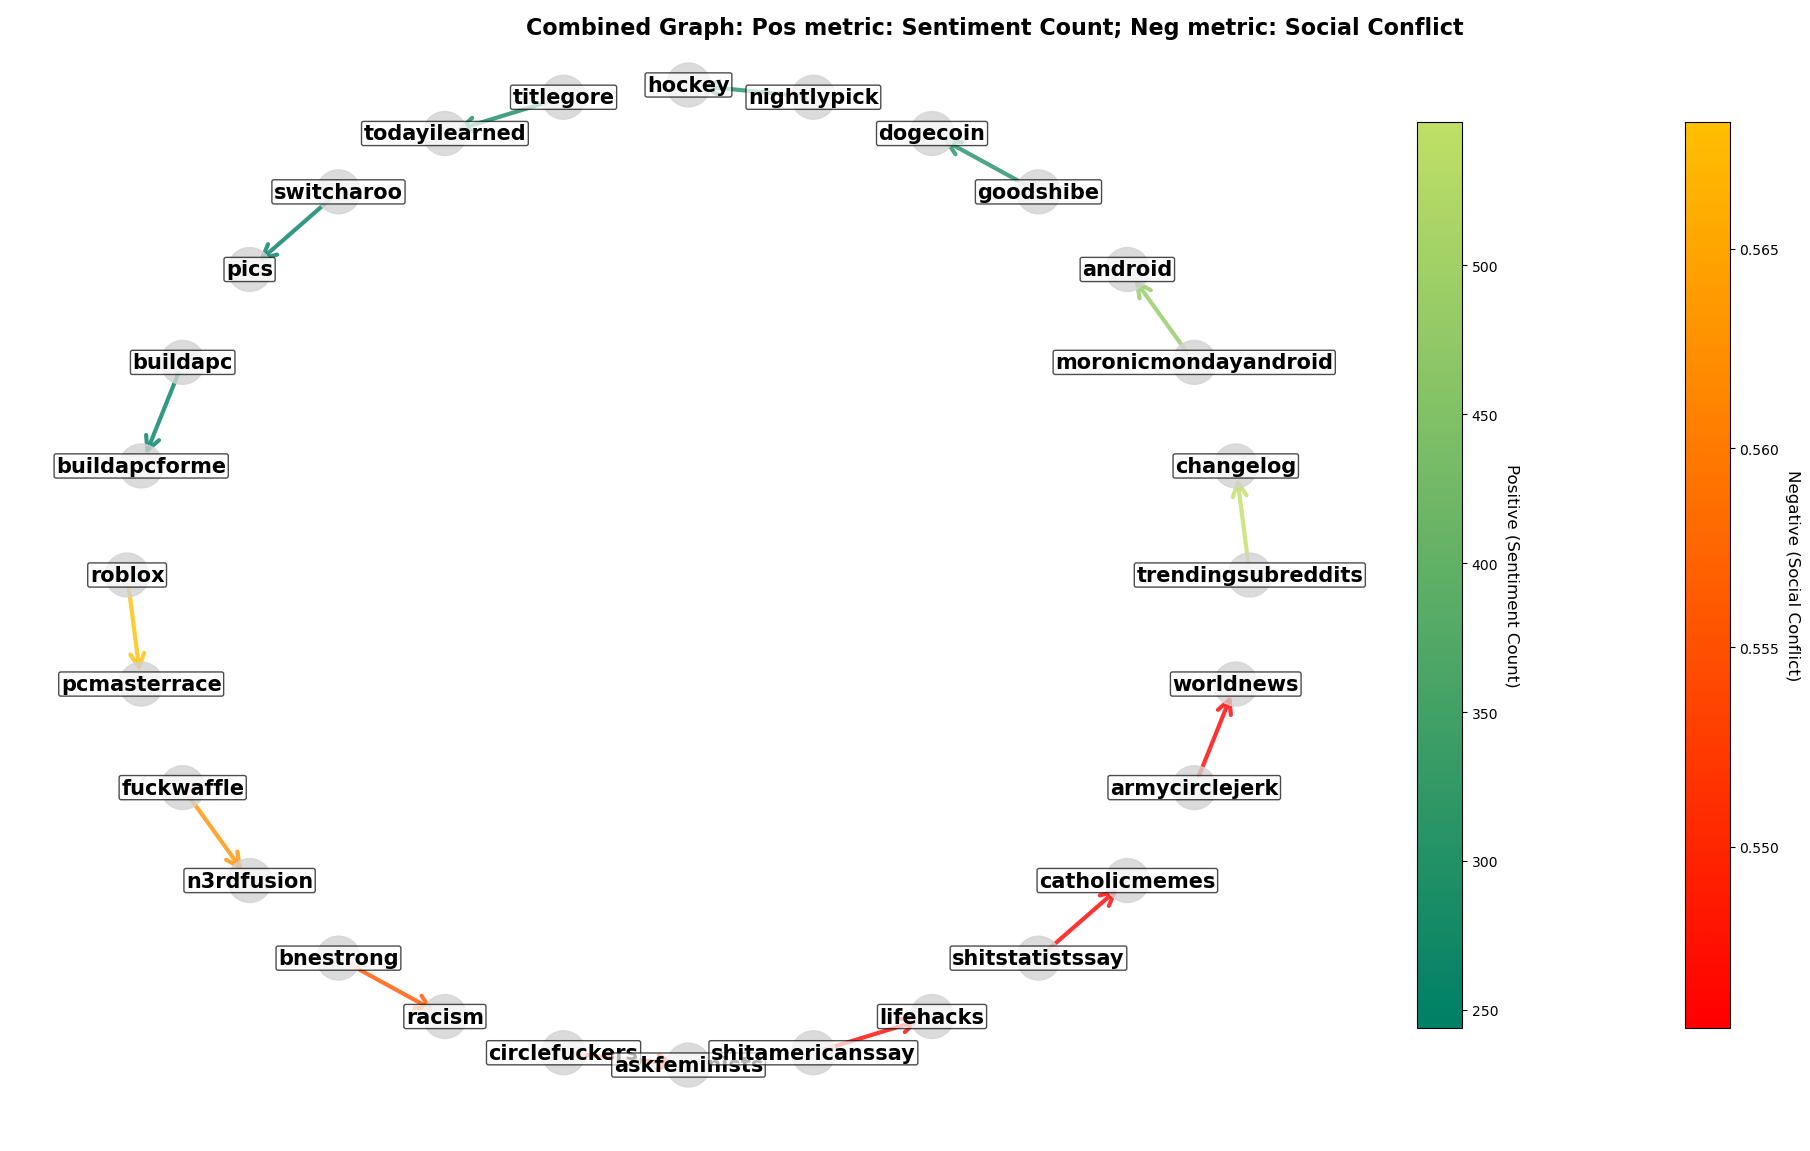

In [5]:
from src.analysis.sentiment_graphs.create_sentiment_graph import create_and_visualize_combined_graph

create_and_visualize_combined_graph(G, metric_pos='sentiment_ratio', metric_neg='sentiment_ratio', top_n_neg=7, top_n_pos=7, show=True)
create_and_visualize_combined_graph(G, metric_pos='sentiment_frequency', metric_neg='direct_hate_score', top_n_neg=7, top_n_pos=7, show=True)
create_and_visualize_combined_graph(G, metric_pos='relative_sentiment', metric_neg='aggressive_communication', top_n_neg=7, top_n_pos=7, show=True)
create_and_visualize_combined_graph(G, metric_pos='sentiment_intensity', metric_neg='emotional_toxicity', top_n_neg=7, top_n_pos=7, show=True)
create_and_visualize_combined_graph(G, metric_pos='sentiment_count', metric_neg='social_conflict', top_n_neg=7, top_n_pos=7, show=True)
